# 07 · Regresión Huber + L2 + interacciones y preselección territorial

**Autora**

Alba Malca.

**Objetivo y alcance**

La libreta estima el cambio de velocidad media de descarga móvil entre dos trimestres
consecutivos y reconstruye la velocidad del siguiente trimestre. El algoritmo y sus
transformaciones de aprendizaje se implementan exclusivamente mediante Spark MLlib.
La regresión conserva una relación lineal en sus coeficientes e incorpora tres
interacciones explícitas para representar relaciones entre predictores.

La pérdida Huber combina un tratamiento cuadrático de residuos pequeños con uno lineal
de residuos grandes. Su umbral depende de `epsilon` y de la escala residual estimada;
no representa un número fijo de Mbps. La regularización L2 limita los coeficientes.
La robustez no identifica automáticamente errores de medición ni garantiza mejoras
ante cambios reales extremos o valores atípicos de los predictores.

**Entorno y ejecución**

La libreta corresponde al kernel **American Tower - PySpark** en EMR con Spark 3.5.x.
Se utiliza la sesión Spark disponible o se crea una sesión YARN sin imponer una
cantidad particular de ejecutores. No se instalan paquetes ni se modifica el entorno.
NumPy, Pandas y las bibliotecas geoespaciales existentes se reservan para tablas,
exportación y visualización; el ajuste y las transformaciones del modelo usan Spark.
La libreta se entrega sin ejecutar. Su ejecución posterior ajustará modelos y
escribirá artefactos y evidencias en S3; la publicación Gold se controla en configuración.

**Evaluación temporal**

Se reproducen los pares del notebook 05: orígenes desde 2020 y año objetivo de
entrenamiento 2020–2022, validación 2023 y prueba 2024. El historial de 2019 aporta
únicamente rezagos en esta evaluación. La imputación, codificación y estandarización
se aprenden con entrenamiento. La selección de parámetros usa solo validación.
Las etapas L2, Huber + L2 y Huber + L2 + interacciones permiten examinar sus aportes.
El modelo principal mantiene las interacciones aunque una referencia resulte mejor;
los resultados deberán informar esa limitación sin asumir superioridad.

WorldPop 2020 se trata como contexto fijo retrospectivo. No se reproduce la fecha
histórica exacta de publicación de ese insumo. OSIPTEL 2023 interviene únicamente
en el índice territorial actual y no se incorpora al entrenamiento retrospectivo.
El GBT del notebook 06 permanece independiente; sus métricas publicadas no sustituyen
una comparación con preparación y pares homogéneos.

**Referencia técnica**

La configuración utiliza la [regresión nativa de Spark 3.5](https://github.com/apache/spark/blob/v3.5.0/mllib/src/main/scala/org/apache/spark/ml/regression/LinearRegression.scala),
que admite Huber con regularización L2 y optimización iterativa. Las métricas y el
mapa se producirán al ejecutar la libreta; no se incluyen resultados supuestos.

**Configuración de la corrida**

La autora se registra como Alba Malca. Los modelos de evaluación y producción se
almacenan por corrida. El identificador `huber_l2_interacciones` separa sus salidas
de las de otros modelos. La publicación trimestral Gold conserva un archivo propio.

In [1]:
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import shutil
import subprocess
import sys
import time
import uuid
from contextlib import ExitStack
from datetime import date, datetime, timezone
from io import BytesIO
from pathlib import Path, PurePosixPath

import boto3
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import Image, display

MODEL_NAME = "huber_l2_interacciones"
MODEL_AUTHOR = "Alba Malca"
REGION = os.environ.get("AWS_REGION", "us-east-1")
OPERATIONS_BUCKET = os.environ.get(
    "AT_OPERATIONS_BUCKET", "american-tower-dev-operations-1dd72256126674a5893dfca3df"
)
GOLD_BUCKET = os.environ.get(
    "AT_GOLD_BUCKET", "american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee"
)
ARTIFACTS_BUCKET = os.environ.get(
    "AT_ARTIFACTS_BUCKET", "american-tower-dev-artifacts-74d32893263161eaef72faf57a"
)
GOLD_RUN_URI = os.environ.get(
    "AT_GOLD_RUN_URI",
    f"s3://{OPERATIONS_BUCKET}/run_id=20261125T073334Z-7ea4f607ff/gold/_SUCCESS.json",
)
RUN_ID = f"{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')}-{uuid.uuid4().hex[:10]}"
EXPECTED_DISTRICTS = 1890
SEED = 42
PUBLISH_PREDICTIONS_TO_GOLD = True
MIN_TESTS = 10
MIN_TILES = 2
TOP_K = 50
PRIORITY_WEIGHTS = (0.40, 0.35, 0.25)

CACHE_DIR = Path(os.environ.get("AT_CACHE_DIR", "/mnt/american-tower-cache")) / MODEL_NAME / RUN_ID
CACHE_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_OUTPUT_DIR = Path(os.environ.get("AT_OUTPUT_DIR", str(CACHE_DIR / "salidas")))
LOCAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_ROOT = f"s3://{ARTIFACTS_BUCKET}/models/{MODEL_NAME}/run_id={RUN_ID}"
EVAL_MODEL_URI = f"{MODEL_ROOT}/evaluacion"
PROD_MODEL_URI = f"{MODEL_ROOT}/productivo"
OUT_OPS_ROOT = f"s3://{OPERATIONS_BUCKET}/run_id={RUN_ID}/modelo_{MODEL_NAME}"
PREDICTIONS_GOLD_KEY = f"predicciones_modelos/modelo_{MODEL_NAME}.parquet"


def show_values(values):
    display(pd.DataFrame(list(values.items()), columns=["Indicador", "Valor"]))


if Path(sys.prefix).resolve() != Path("/opt/american-tower/venv").resolve():
    raise RuntimeError(
        f"El kernel está usando {sys.executable} (entorno {sys.prefix}). "
        "Debe seleccionarse American Tower - PySpark con el entorno /opt/american-tower/venv."
    )

dependency_versions = {
    package: metadata.version(package)
    for package in ("boto3", "numpy", "pandas", "pyarrow", "matplotlib")
}

show_values({"Modelo": MODEL_NAME, "Autora": MODEL_AUTHOR, "Corrida": RUN_ID,
             "Manifiesto Gold": GOLD_RUN_URI, "Bibliotecas de soporte": dependency_versions,
             "Publicación Gold": PUBLISH_PREDICTIONS_TO_GOLD,
             "Salidas locales": str(LOCAL_OUTPUT_DIR)})

,Indicador,Valor
0,Modelo,huber_l2_interacciones
1,Autora,Alba Malca
2,Corrida,20261128T113553Z-c922621085
3,Manifiesto Gold,s3://american-tower-dev-operations-1dd72256126...
4,Bibliotecas de soporte,"{'boto3': '1.42.97', 'numpy': '1.26.4', 'panda..."
5,Publicación Gold,True
6,Salidas locales,/mnt/american-tower-cache/huber_l2_interaccion...


**Linaje y sesión Spark**

Los manifiestos se leen mediante el rol de la instancia. Se reutiliza la sesión Spark
si existe y se conservan sus recursos. Una sesión nueva utiliza YARN y registra
eventos por corrida. No se realizan comprobaciones de paquetes externos en los nodos
ni se utilizan tareas en modo barrera. Solo se detiene la sesión si fue creada por
esta libreta; las tablas almacenadas temporalmente se liberan al finalizar.

In [2]:
s3 = boto3.client("s3", region_name=REGION)


def s3_path(uri):
    if not isinstance(uri, str) or not uri.startswith("s3://"):
        raise ValueError(f"URI S3 inválida: {uri}")
    bucket, _, key = uri[5:].partition("/")
    if not bucket or not key:
        raise ValueError(f"Se requiere una ruta de objeto S3: {uri}")
    return bucket, key


def read_json_s3(uri):
    bucket, key = s3_path(uri)
    with s3.get_object(Bucket=bucket, Key=key)["Body"] as body:
        return json.loads(body.read().decode("utf-8"))


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if isinstance(value, float) and not math.isfinite(value):
        return None
    if isinstance(value, (date, datetime, Path)):
        return str(value)
    return value


def save_json_s3(uri, payload):
    bucket, key = s3_path(uri)
    body = json.dumps(json_safe(payload), ensure_ascii=False, indent=2, allow_nan=False).encode("utf-8")
    s3.put_object(Bucket=bucket, Key=key, Body=body, ContentType="application/json")
    return uri


def persist_figure(fig, name, show=True):
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=180, bbox_inches="tight", facecolor="white")
        data = buffer.getvalue()
    path = LOCAL_OUTPUT_DIR / name
    path.write_bytes(data)
    bucket, key = s3_path(f"{OUT_OPS_ROOT}/{name}")
    s3.upload_file(str(path), bucket, key, ExtraArgs={"ContentType": "image/png"})
    plt.close(fig)
    if show:
        display(Image(data=data))
    return {"local": str(path), "s3": f"s3://{bucket}/{key}"}


gold_manifest = read_json_s3(GOLD_RUN_URI)
bronze_manifest = read_json_s3(gold_manifest["bronze_manifest_uri"])
if s3_path(gold_manifest["panel_uri"])[0] != GOLD_BUCKET:
    raise ValueError("El bucket Gold configurado difiere del manifiesto de entrada.")

SPARK_HOME = Path("/usr/lib/spark")
if not SPARK_HOME.is_dir():
    raise RuntimeError("La libreta requiere el nodo primario de EMR con Spark instalado.")
os.environ["SPARK_HOME"] = str(SPARK_HOME)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
py4j_zips = sorted((SPARK_HOME / "python/lib").glob("py4j-*.zip"))
if not py4j_zips:
    raise RuntimeError("No se encontró Py4J en el entorno de Spark.")
sys.path[:0] = [str(SPARK_HOME / "python"), str(py4j_zips[0])]

from pyspark import SparkContext
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import Imputer, OneHotEncoder, SQLTransformer, StringIndexer, VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.sql import SparkSession, Window, functions as F

owns_spark_session = SparkContext._active_spark_context is None
events_uri = None
if owns_spark_session:
    events_key = f"run_id={RUN_ID}/eventos_spark/"
    s3.put_object(Bucket=OPERATIONS_BUCKET, Key=events_key, Body=b"")
    events_uri = f"s3://{OPERATIONS_BUCKET}/{events_key}"
    spark = (
        SparkSession.builder.master("yarn").appName(f"american-tower-{MODEL_NAME}")
        .config("spark.pyspark.python", sys.executable)
        .config("spark.executorEnv.PYSPARK_PYTHON", sys.executable)
        .config("spark.sql.session.timeZone", "UTC")
        .config("spark.eventLog.enabled", "true")
        .config("spark.eventLog.dir", events_uri)
        .getOrCreate()
    )
else:
    spark = SparkSession.builder.getOrCreate()
    events_uri = spark.sparkContext.getConf().get("spark.eventLog.dir", None)
spark.sparkContext.setLogLevel("WARN")
resources = ExitStack()
if owns_spark_session:
    resources.callback(spark.stop)

from IPython import get_ipython


def close_on_failure(result):
    if result.error_before_exec or result.error_in_exec:
        resources.close()


ipython_events = get_ipython().events
ipython_events.register("post_run_cell", close_on_failure)
resources.callback(ipython_events.unregister, "post_run_cell", close_on_failure)
if not spark.version.startswith("3.5."):
    resources.close()
    raise RuntimeError(f"Se requiere Spark 3.5.x; se encontró {spark.version}.")
spark_environment = {
    "spark_version": spark.version,
    "application_id": spark.sparkContext.applicationId,
    "default_parallelism": spark.sparkContext.defaultParallelism,
    "owns_session": owns_spark_session,
    "configuration": {
        key: spark.sparkContext.getConf().get(key, "no especificado")
        for key in ("spark.executor.instances", "spark.executor.cores", "spark.task.cpus",
                    "spark.dynamicAllocation.enabled", "spark.executor.memory")
    },
}
show_values({"Aplicación": spark.sparkContext.applicationId, "Spark": spark.version,
             "Sesión creada por la libreta": owns_spark_session,
             "Eventos": events_uri, "Modelo productivo": PROD_MODEL_URI})

/opt/american-tower/venv/lib64/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
Nov 28, 2026 11:35:55 AM org.apache.spark.launcher.Log4jHotPatchOption staticJavaAgentOption

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/28 11:35:59 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.


,Indicador,Valor
0,Aplicación,application_1795865364442_0001
1,Spark,3.5.0-amzn-1
2,Sesión creada por la libreta,True
3,Eventos,s3://american-tower-dev-operations-1dd72256126...
4,Modelo productivo,s3://american-tower-dev-artifacts-74d328932631...


**Contrato Gold y contexto territorial actual**

El panel debe conservar una fila por distrito y trimestre, incluso cuando no existe
medición. La ausencia de velocidad no se transforma en cero. La cobertura declarada
de OSIPTEL se conserva con su fecha y se imputa únicamente para construir el índice
actual, mediante la mediana departamental y, en su defecto, la nacional.

In [3]:
def cached(frame):
    frame = frame.cache()
    resources.callback(frame.unpersist)
    return frame


def require_columns(frame, columns, name):
    missing = set(columns) - set(frame.columns)
    if missing:
        raise ValueError(f"Faltan columnas en {name}: {sorted(missing)}")


def finite_col(name):
    column = F.col(name).cast("double")
    return column.isNotNull() & ~F.isnan(column) & (F.abs(column) < F.lit(float("inf")))


panel = cached(spark.read.parquet(gold_manifest["panel_uri"]))
context = cached(spark.read.parquet(gold_manifest["context_uri"]))
require_columns(panel, ["ubigeo", "departamento", "provincia", "distrito", "period_id",
                        "year", "quarter", "vel_descarga_mbps", "tests", "observado",
                        "teselas_observadas", "superficie_km2"], "panel_distrital")
require_columns(context, ["ubigeo", "departamento", "poblacion_2020", "centros_en_reporte",
                          "centros_con_dato_4g", "centros_con_4g_declarada",
                          "periodo_referencia", "fecha_corte_fuente"], "contexto_territorial")
panel_stats = panel.agg(
    F.count("*").alias("filas"),
    F.count_distinct(F.struct("ubigeo", "period_id")).alias("claves"),
    F.count_distinct("ubigeo").alias("distritos"),
    F.count_distinct("period_id").alias("trimestres"),
    F.count("vel_descarga_mbps").alias("observadas"),
).first().asDict()
if (panel_stats["distritos"] != EXPECTED_DISTRICTS
        or panel_stats["filas"] != panel_stats["claves"]
        or panel_stats["filas"] != EXPECTED_DISTRICTS * panel_stats["trimestres"]):
    raise ValueError("El panel no cumple el universo distrital o su granularidad.")
if panel.filter("ubigeo IS NULL OR period_id IS NULL OR observado IS NULL").limit(1).count():
    raise ValueError("El panel contiene claves o indicadores de observación nulos.")
if panel.filter(
    (F.col("year") != F.floor(F.col("period_id") / 4))
    | (F.col("quarter") != (F.col("period_id") % 4) + 1)
).limit(1).count():
    raise ValueError("La codificación temporal del panel difiere de year * 4 + quarter - 1.")
if panel.filter(
    F.col("observado") != F.col("vel_descarga_mbps").isNotNull()
).limit(1).count():
    raise ValueError("El indicador observado no coincide con la disponibilidad de velocidad.")
if panel.filter(
    F.col("observado") & (~finite_col("vel_descarga_mbps")
                        | (F.col("vel_descarga_mbps") <= 0)
                        | ~finite_col("tests") | (F.col("tests") <= 0))
).limit(1).count():
    raise ValueError("Se encontraron mediciones observadas inválidas.")
periods = sorted(row.period_id for row in panel.select("period_id").distinct().collect())
if periods != list(range(periods[0], periods[-1] + 1)):
    raise ValueError("El calendario distrital debe incluir todos los trimestres consecutivos.")
context_stats = context.agg(
    F.count("*").alias("filas"), F.count_distinct("ubigeo").alias("claves"),
    F.count("poblacion_2020").alias("con_poblacion"),
    F.count("centros_en_reporte").alias("con_osiptel"),
).first().asDict()
if context_stats["filas"] != EXPECTED_DISTRICTS or context_stats["claves"] != EXPECTED_DISTRICTS:
    raise ValueError("El contexto no contiene una fila única por distrito.")
if (panel.select("ubigeo").distinct().join(context.select("ubigeo"), "ubigeo", "left_anti")
        .limit(1).count()):
    raise ValueError("Existen distritos del panel sin correspondencia en el contexto.")
if context.filter(~finite_col("poblacion_2020") | (F.col("poblacion_2020") < 0)).limit(1).count():
    raise ValueError("La población de contexto contiene valores ausentes o inválidos.")

coverage_raw = context.select(
    "ubigeo", "departamento", "poblacion_2020", "centros_en_reporte",
    "periodo_referencia", "fecha_corte_fuente",
    F.when(F.col("centros_con_dato_4g") > 0,
           100.0 * F.col("centros_con_4g_declarada") / F.col("centros_con_dato_4g"))
    .alias("pct_cobertura_4g_raw"),
)
if coverage_raw.filter(~F.col("pct_cobertura_4g_raw").between(0, 100)).limit(1).count():
    raise ValueError("La cobertura declarada contiene porcentajes fuera de rango.")
coverage_dates = context.select("periodo_referencia", "fecha_corte_fuente").dropna().distinct().collect()
if len(coverage_dates) != 1:
    raise ValueError("El contexto debe identificar una sola instantánea OSIPTEL.")
coverage_snapshot = coverage_dates[0].asDict()
valid_cov = coverage_raw.filter(F.col("pct_cobertura_4g_raw").isNotNull())
national_cov = valid_cov.agg(F.percentile_approx("pct_cobertura_4g_raw", 0.5).alias("m")).first().m
if national_cov is None:
    raise ValueError("No existe cobertura interpretable para construir el índice territorial.")
dept_cov = valid_cov.groupBy("departamento").agg(
    F.percentile_approx("pct_cobertura_4g_raw", 0.5).alias("mediana_cobertura_depto")
)
priority_context = cached(
    coverage_raw.join(dept_cov, "departamento", "left")
    .withColumn("pct_cobertura_4g_imputada", F.coalesce(
        "pct_cobertura_4g_raw", "mediana_cobertura_depto", F.lit(float(national_cov))))
    .withColumn("cobertura_imputada", F.col("pct_cobertura_4g_raw").isNull())
    .withColumn("en_punto_ciego_osiptel", F.col("centros_en_reporte").isNull())
    .drop("mediana_cobertura_depto")
)
show_values({**panel_stats, "Contexto": context_stats,
             "Instantánea OSIPTEL usada solo en priorización": coverage_snapshot})

,Indicador,Valor
0,filas,54810
1,claves,54810
2,distritos,1890
3,trimestres,29
4,observadas,41434
5,Contexto,"{'filas': 1890, 'claves': 1890, 'con_poblacion..."
6,Instantánea OSIPTEL usada solo en priorización,"{'periodo_referencia': '202303', 'fecha_corte_..."


**Características temporales y particiones cronológicas**

Los rezagos y las ventanas recientes se calculan antes de filtrar mediciones para
respetar los trimestres ausentes. Se mantienen los indicadores de rezagos faltantes.
Las ausencias se imputan con medianas aprendidas únicamente en entrenamiento;
la falta de velocidad no se interpreta como una medición de cero.

La etiqueta es `velocidad(t+1) − velocidad(t)`. El peso de ajuste es `log1p(tests_t)`
y las métricas se calculan sin ponderar, sobre la velocidad futura reconstruida.
Los conteos esperados corresponden al manifiesto Gold fijado en configuración;
otro manifiesto conserva la misma regla temporal y reporta sus propios conteos.

In [4]:
FEATURE_NUMERIC_COLS = [
    "log_vel_t", "log_vel_lag1", "log_vel_lag2", "log_vel_lag4",
    "log_vel_media_4t", "vel_std_4t", "delta_vel_1t", "vel_ratio_media_4t",
    "vel_ratio_depto_t", "log_tests_t", "teselas_observadas_t", "quarter_objetivo",
    "historial_observado_4t", "sin_lag1", "sin_lag2", "sin_lag4",
    "log_poblacion_2020", "superficie_km2", "log_densidad_hab_km2",
]
district_window = Window.partitionBy("ubigeo").orderBy("period_id")
recent_window = district_window.rowsBetween(-3, 0)
department_speed = panel.filter("observado").groupBy("departamento", "period_id").agg(
    F.percentile_approx("vel_descarga_mbps", 0.5, 10000).alias("vel_mediana_depto_t")
)
features = (
    panel.join(context.select("ubigeo", "poblacion_2020"), "ubigeo", "left")
    .join(department_speed, ["departamento", "period_id"], "left")
    .withColumn("vel_t", F.col("vel_descarga_mbps"))
    .withColumn("vel_lag1", F.lag("vel_descarga_mbps", 1).over(district_window))
    .withColumn("vel_lag2", F.lag("vel_descarga_mbps", 2).over(district_window))
    .withColumn("vel_lag4", F.lag("vel_descarga_mbps", 4).over(district_window))
    .withColumn("vel_media_4t", F.avg("vel_descarga_mbps").over(recent_window))
    .withColumn("vel_std_4t", F.stddev_pop("vel_descarga_mbps").over(recent_window))
    .withColumn("historial_observado_4t", F.count("vel_descarga_mbps").over(recent_window).cast("double"))
    .withColumn("objetivo", F.lead("vel_descarga_mbps", 1).over(district_window))
    .withColumn("period_id_objetivo", F.col("period_id") + 1)
    .withColumn("year_objetivo", F.floor(F.col("period_id_objetivo") / 4).cast("int"))
    .withColumn("quarter_objetivo", ((F.col("period_id_objetivo") % 4) + 1).cast("int"))
    .withColumn("objetivo_delta_mbps", F.col("objetivo") - F.col("vel_t"))
    .withColumn("delta_vel_1t", F.col("vel_t") - F.col("vel_lag1"))
    .withColumn("vel_ratio_media_4t", F.col("vel_t") / F.greatest(F.col("vel_media_4t"), F.lit(0.5)))
    .withColumn("vel_ratio_depto_t", F.col("vel_t") / F.greatest(F.col("vel_mediana_depto_t"), F.lit(0.5)))
    .withColumn("log_tests_t", F.log1p(F.col("tests").cast("double")))
    .withColumn("teselas_observadas_t", F.col("teselas_observadas").cast("double"))
    .withColumn("sample_weight", F.log1p(F.col("tests").cast("double")))
    .withColumn("log_poblacion_2020", F.log1p("poblacion_2020"))
    .withColumn("log_densidad_hab_km2", F.when(
        F.col("superficie_km2") > 0, F.log1p(F.col("poblacion_2020") / F.col("superficie_km2"))))
)
for lag in (1, 2, 4):
    features = features.withColumn(f"sin_lag{lag}", F.col(f"vel_lag{lag}").isNull().cast("double"))
for source, target in [
    ("vel_t", "log_vel_t"), ("vel_lag1", "log_vel_lag1"),
    ("vel_lag2", "log_vel_lag2"), ("vel_lag4", "log_vel_lag4"),
    ("vel_media_4t", "log_vel_media_4t"),
]:
    features = features.withColumn(target, F.log1p(F.col(source)))
features_full = cached(features)
all_pairs = cached(features_full.filter(finite_col("vel_t") & finite_col("objetivo")))
evaluation_pairs = cached(
    all_pairs.filter((F.col("year") >= 2020) & F.col("year_objetivo").between(2020, 2024))
    .withColumn("particion", F.when(F.col("year_objetivo") <= 2022, "entrenamiento")
                .when(F.col("year_objetivo") == 2023, "validacion").otherwise("prueba"))
)
partition_rows = [row.asDict() for row in evaluation_pairs.groupBy("particion", "year_objetivo").agg(
    F.count("*").alias("pares"), F.count_distinct("ubigeo").alias("distritos")
).orderBy("year_objetivo").collect()]
display(pd.DataFrame(partition_rows))
train_df = cached(evaluation_pairs.filter("particion = 'entrenamiento'"))
val_df = cached(evaluation_pairs.filter("particion = 'validacion'"))
test_df = cached(evaluation_pairs.filter("particion = 'prueba'"))
partition_sizes = {name: frame.count() for name, frame in [
    ("entrenamiento", train_df), ("validacion", val_df), ("prueba", test_df)
]}
if min(partition_sizes.values()) < 2:
    raise ValueError("Las particiones no contienen pares suficientes para ajustar y evaluar el modelo.")
show_values({**partition_sizes, "Pares productivos": all_pairs.count(),
             "Predictores": FEATURE_NUMERIC_COLS + ["departamento codificado"]})
PINNED_GOLD_RUN_ID = "20261125T073334Z-7ea4f607ff"
expected_sizes = {"entrenamiento": 13660, "validacion": 5248, "prueba": 5666}
if PINNED_GOLD_RUN_ID in GOLD_RUN_URI and partition_sizes != expected_sizes:
    raise ValueError(f"Los pares difieren del notebook 05: {partition_sizes}; esperados {expected_sizes}.")
if all_pairs.filter(~finite_col("sample_weight") | (F.col("sample_weight") <= 0)).limit(1).count():
    raise ValueError("Los pesos de entrenamiento deben ser positivos y finitos.")

26/11/28 11:36:32 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,particion,year_objetivo,pares,distritos
0,entrenamiento,2020,3190,1335
1,entrenamiento,2021,5126,1547
2,entrenamiento,2022,5344,1574
3,validacion,2023,5248,1547
4,prueba,2024,5666,1645


,Indicador,Valor
0,entrenamiento,13660
1,validacion,5248
2,prueba,5666
3,Pares productivos,35557
4,Predictores,"[log_vel_t, log_vel_lag1, log_vel_lag2, log_ve..."


**Preprocesamiento y comparación por etapas**

Los valores no finitos de predictores se convierten en ausencias. Se aplica imputación
por mediana y codificación departamental aprendidas exclusivamente con entrenamiento.
Una columna sin valores válidos detiene el ajuste con su nombre. Las tres interacciones
se calculan después de imputar; no se generan todos los cruces posibles.

Las etapas comparadas son regresión multivariable L2, Huber + L2 y Huber + L2 con
interacciones. Se exploran tres regularizaciones y tres valores de epsilon en Huber,
con 21 ajustes en total. Cada etapa selecciona por MAE de validación, con desempates
por RMSE, mayor regularización y menor epsilon. El modelo principal es la tercera etapa.
La estandarización interna de `LinearRegression` usa únicamente los datos de ajuste.

Se conservan el historial del objetivo, el número de iteraciones y la escala residual
de cada candidato. Alcanzar el límite de iteraciones se informa como advertencia y
requiere revisar la convergencia. Un candidato fallido se registra y se excluye;
si una etapa carece de candidatos válidos, se detiene el proceso.

In [5]:
INTERACTIONS = [
    ("inter_vel_densidad", "log_vel_t", "log_densidad_hab_km2"),
    ("inter_vel_pruebas", "log_vel_t", "log_tests_t"),
    ("inter_delta_historial", "delta_vel_1t", "historial_observado_4t"),
]
STAGES = [
    {"id": "l2", "name": "Regresión multivariable L2", "loss": "squaredError", "interactions": False},
    {"id": "huber_l2", "name": "Huber + L2", "loss": "huber", "interactions": False},
    {"id": MODEL_NAME, "name": "Huber + L2 + interacciones", "loss": "huber", "interactions": True},
]
REGULARIZATIONS = [0.01, 0.1, 1.0]
EPSILONS = [1.2, 1.35, 1.8]
MAX_ITER = 300
TOLERANCE = 1e-6


def assert_imputable(frame, description):
    counts = frame.agg(*[
        F.sum(F.when(finite_col(name), 1).otherwise(0)).alias(name)
        for name in FEATURE_NUMERIC_COLS
    ]).first().asDict()
    empty = [name for name, count in counts.items() if not count]
    if empty:
        raise ValueError(f"Predictores sin valores finitos en {description}: {empty}")


def preprocessing_pipeline(include_interactions):
    # Los nombres de salida conservan la correspondencia con los coeficientes.
    clean_expressions = [
        f"CASE WHEN `{name}` IS NULL OR ISNAN(CAST(`{name}` AS DOUBLE)) "
        f"OR ABS(CAST(`{name}` AS DOUBLE)) = CAST('Infinity' AS DOUBLE) "
        f"THEN CAST(NULL AS DOUBLE) ELSE CAST(`{name}` AS DOUBLE) END AS `{name}_limpia`"
        for name in FEATURE_NUMERIC_COLS
    ]
    stages = [
        SQLTransformer(statement="SELECT *, " + ", ".join(clean_expressions) + " FROM __THIS__"),
        Imputer(strategy="median", inputCols=[f"{name}_limpia" for name in FEATURE_NUMERIC_COLS],
                outputCols=[f"{name}_imputada" for name in FEATURE_NUMERIC_COLS]),
        StringIndexer(inputCol="departamento", outputCol="departamento_idx", handleInvalid="keep"),
        OneHotEncoder(inputCols=["departamento_idx"], outputCols=["departamento_ohe"],
                      dropLast=False, handleInvalid="keep"),
    ]
    inputs = [f"{name}_imputada" for name in FEATURE_NUMERIC_COLS]
    if include_interactions:
        products = [f"`{left}_imputada` * `{right}_imputada` AS `{name}`"
                    for name, left, right in INTERACTIONS]
        stages.append(SQLTransformer(statement="SELECT *, " + ", ".join(products) + " FROM __THIS__"))
        inputs += [name for name, _, _ in INTERACTIONS]
    stages.append(VectorAssembler(inputCols=inputs + ["departamento_ohe"],
                                  outputCol="features", handleInvalid="error"))
    return Pipeline(stages=stages)


def regression_estimator(loss, parameters):
    options = dict(featuresCol="features", labelCol="objetivo_delta_mbps",
                   predictionCol="pred_delta_mbps", weightCol="sample_weight",
                   loss=loss, elasticNetParam=0.0, solver="l-bfgs",
                   standardization=True, fitIntercept=True, maxIter=MAX_ITER, tol=TOLERANCE,
                   regParam=parameters["regParam"])
    if loss == "huber":
        options["epsilon"] = parameters["epsilon"]
    return LinearRegression(**options)


def fit_diagnostics(model):
    history = [float(value) for value in model.summary.objectiveHistory]
    if not history or not all(math.isfinite(value) for value in history):
        raise ValueError("El historial de optimización está vacío o contiene valores no finitos.")
    if (not math.isfinite(float(model.intercept))
            or not all(math.isfinite(float(value)) for value in model.coefficients)):
        raise ValueError("El ajuste produjo coeficientes no finitos.")
    scale = float(model.scale) if model.getLoss() == "huber" else None
    if scale is not None and (not math.isfinite(scale) or scale <= 0):
        raise ValueError("La escala residual de Huber debe ser positiva y finita.")
    iterations = int(model.summary.totalIterations)
    return {"iterations": iterations, "iteration_limit_reached": iterations >= MAX_ITER,
            "objective_history": history, "residual_scale": scale}
def regression_metrics(frame, prediction_col="prediction"):
    summary = frame.agg(
        F.count("*").alias("n"),
        F.sum(F.when(~finite_col(prediction_col), 1).otherwise(0)).alias("invalidas"),
        F.avg(F.abs(F.col(prediction_col) - F.col("objetivo"))).alias("mae_mbps"),
        F.avg(F.pow(F.col(prediction_col) - F.col("objetivo"), 2)).alias("mse"),
        F.avg(F.col(prediction_col) - F.col("objetivo")).alias("sesgo_mbps"),
        F.var_pop("objetivo").alias("varianza"),
    ).first().asDict()
    if not summary["n"]:
        return {"n": 0, "mae_mbps": None, "rmse_mbps": None, "sesgo_mbps": None, "r2": None}
    if summary["invalidas"]:
        raise ValueError("Se generaron predicciones no finitas.")
    return {"n": int(summary["n"]), "mae_mbps": float(summary["mae_mbps"]),
            "rmse_mbps": math.sqrt(summary["mse"]), "sesgo_mbps": float(summary["sesgo_mbps"]),
            "r2": 1.0 - summary["mse"] / summary["varianza"] if summary["varianza"] else None}


postprocessor = SQLTransformer(statement=(
    "SELECT *, CASE WHEN pred_delta_mbps IS NULL OR ISNAN(pred_delta_mbps) "
    "OR ABS(pred_delta_mbps) = CAST('Infinity' AS DOUBLE) THEN CAST(NULL AS DOUBLE) "
    "ELSE GREATEST(0.0, vel_t + pred_delta_mbps) END AS prediction FROM __THIS__"
))



assert_imputable(train_df, "entrenamiento")
tuning_rows = []
stage_models = {}
stage_parameters = {}
stage_diagnostics = {}
stage_preprocessors = {}
candidate_id = 0
for stage in STAGES:
    preprocessor = preprocessing_pipeline(stage["interactions"]).fit(train_df)
    stage_preprocessors[stage["id"]] = preprocessor
    train_features = cached(preprocessor.transform(train_df))
    val_features = cached(preprocessor.transform(val_df))
    train_features.count()
    val_features.count()
    best_key = None
    best_model = None
    for regularization in REGULARIZATIONS:
        for epsilon in (EPSILONS if stage["loss"] == "huber" else [None]):
            candidate_id += 1
            parameters = {"regParam": regularization}
            if epsilon is not None:
                parameters["epsilon"] = epsilon
            start = time.perf_counter()
            try:
                candidate = regression_estimator(stage["loss"], parameters).fit(train_features)
                fit_seconds = time.perf_counter() - start
                diagnostics = fit_diagnostics(candidate)
                candidate_scored = postprocessor.transform(candidate.transform(val_features))
                metrics = regression_metrics(candidate_scored)
                if not all(math.isfinite(metrics[name]) for name in ("mae_mbps", "rmse_mbps")):
                    raise ValueError("Las métricas de validación no son finitas.")
            except Exception as error:
                # Se conserva el fallo y se continúa con otro candidato; no se oculta una etapa fallida.
                tuning_rows.append({"candidato": candidate_id, "etapa": stage["id"], **parameters,
                                    "estado": "fallido", "error": f"{type(error).__name__}: {error}",
                                    "fit_seconds": time.perf_counter() - start})
                print(f"Candidato {candidate_id}/21 · {stage['name']} · ajuste fallido")
                continue
            tuning_rows.append({"candidato": candidate_id, "etapa": stage["id"], **parameters,
                                "estado": "valido", "fit_seconds": fit_seconds, **metrics, **diagnostics})
            selection_key = (metrics["mae_mbps"], metrics["rmse_mbps"], -regularization,
                             epsilon if epsilon is not None else 0.0)
            if best_key is None or selection_key < best_key:
                best_key = selection_key
                best_model = candidate
                stage_parameters[stage["id"]] = dict(parameters)
                stage_diagnostics[stage["id"]] = diagnostics
            print(f"Candidato {candidate_id}/21 · {stage['name']} · MAE: {metrics['mae_mbps']:.3f} Mbps")
            if diagnostics["iteration_limit_reached"]:
                print("Advertencia: se alcanzó el límite de iteraciones; corresponde revisar la convergencia.")
    if best_model is None:
        raise RuntimeError(f"La etapa {stage['name']} no contiene candidatos válidos. Se detiene el proceso.")
    stage_models[stage["id"]] = PipelineModel(stages=preprocessor.stages + [best_model, postprocessor])
    train_features.unpersist()
    val_features.unpersist()

best_parameters = stage_parameters[MODEL_NAME]
eval_preprocessor = stage_preprocessors[MODEL_NAME]
eval_model = stage_models[MODEL_NAME]
eval_regression_model = eval_model.stages[-2]
eval_model.write().save(EVAL_MODEL_URI)
tuning_pdf = pd.DataFrame(tuning_rows)
display(tuning_pdf.drop(columns=["objective_history"], errors="ignore").sort_values(
    ["etapa", "estado", "mae_mbps", "rmse_mbps"], na_position="last"))
show_values({"Parámetros seleccionados por etapa": stage_parameters,
             "Modelo principal de evaluación": EVAL_MODEL_URI})

26/11/28 11:37:00 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/28 11:37:00 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


Candidato 1/21 · Regresión multivariable L2 · MAE: 11.346 Mbps
Candidato 2/21 · Regresión multivariable L2 · MAE: 11.341 Mbps
Candidato 3/21 · Regresión multivariable L2 · MAE: 11.317 Mbps


26/11/28 11:38:08 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


Candidato 4/21 · Huber + L2 · MAE: 11.319 Mbps
Candidato 5/21 · Huber + L2 · MAE: 11.302 Mbps
Candidato 6/21 · Huber + L2 · MAE: 11.263 Mbps
Candidato 7/21 · Huber + L2 · MAE: 11.758 Mbps
Candidato 8/21 · Huber + L2 · MAE: 11.709 Mbps
Candidato 9/21 · Huber + L2 · MAE: 11.617 Mbps
Candidato 10/21 · Huber + L2 · MAE: 12.803 Mbps
Candidato 11/21 · Huber + L2 · MAE: 12.771 Mbps
Candidato 12/21 · Huber + L2 · MAE: 12.721 Mbps
Candidato 13/21 · Huber + L2 + interacciones · MAE: 11.300 Mbps
Candidato 14/21 · Huber + L2 + interacciones · MAE: 11.284 Mbps
Candidato 15/21 · Huber + L2 + interacciones · MAE: 11.249 Mbps
Candidato 16/21 · Huber + L2 + interacciones · MAE: 11.682 Mbps
Candidato 17/21 · Huber + L2 + interacciones · MAE: 11.634 Mbps
Candidato 18/21 · Huber + L2 + interacciones · MAE: 11.550 Mbps
Candidato 19/21 · Huber + L2 + interacciones · MAE: 12.716 Mbps
Candidato 20/21 · Huber + L2 + interacciones · MAE: 12.681 Mbps
Candidato 21/21 · Huber + L2 + interacciones · MAE: 12.625 Mbp

,candidato,etapa,regParam,estado,fit_seconds,n,mae_mbps,rmse_mbps,sesgo_mbps,r2,iterations,iteration_limit_reached,residual_scale,epsilon
5,6,huber_l2,0.01,valido,14.865335,5248,11.263198,18.705131,-2.439646,0.066372,30,False,6.650722,1.80
4,5,huber_l2,0.01,valido,16.912227,5248,11.301515,18.848379,-2.897230,0.052018,33,False,4.392232,1.35
3,4,huber_l2,0.01,valido,17.985864,5248,11.318565,18.903052,-3.057666,0.046510,30,False,3.010127,1.20
8,9,huber_l2,0.10,valido,11.403935,5248,11.617485,19.325626,-2.345150,0.003403,19,False,6.737344,1.80
7,8,huber_l2,0.10,valido,9.855488,5248,11.709176,19.506853,-2.620385,-0.015376,18,False,4.414381,1.35
6,7,huber_l2,0.10,valido,9.716041,5248,11.758371,19.589733,-2.690145,-0.024022,19,False,3.001637,1.20
11,12,huber_l2,1.00,valido,9.341075,5248,12.720867,20.941291,-1.160316,-0.170198,19,False,7.455705,1.80
10,11,huber_l2,1.00,valido,9.374153,5248,12.770993,21.019324,-1.249514,-0.178935,18,False,4.685482,1.35
9,10,huber_l2,1.00,valido,8.804593,5248,12.802514,21.065595,-1.280716,-0.184131,17,False,3.160700,1.20
14,15,huber_l2_interacciones,0.01,valido,16.491485,5248,11.248558,18.678928,-2.512909,0.068986,35,False,6.639229,1.80


,Indicador,Valor
0,Parámetros seleccionados por etapa,"{'l2': {'regParam': 1.0}, 'huber_l2': {'regPar..."
1,Modelo principal de evaluación,s3://american-tower-dev-artifacts-74d328932631...


**Evaluación comparable y diagnóstico de errores**

Se comparan las tres etapas con persistencia y regresión simple. Las referencias
utilizan exactamente los mismos pares. Se presentan todos los pares y el segmento
con diez pruebas y dos teselas en el trimestre de origen. La selección de cada etapa
ya está cerrada antes de consultar prueba. Los desgloses temporales y departamentales
permiten detectar sesgo y heterogeneidad; no habilitan nuevos ajustes sobre 2024.

26/11/28 11:42:08 WARN Instrumentation: [79c526fd] regParam is zero, which might cause numerical instability and overfitting.


,particion,segmento,modelo,n,mae_mbps,rmse_mbps,sesgo_mbps,r2
0,validacion,Todos los pares,Persistencia,5248,13.2788,21.7215,-1.2451,-0.2590
1,validacion,Todos los pares,Regresión lineal simple,5248,11.6445,19.0843,-5.1307,0.0281
2,validacion,Todos los pares,Regresión multivariable L2,5248,11.3169,18.4318,-0.8406,0.0935
3,validacion,Todos los pares,Huber + L2,5248,11.2632,18.7051,-2.4396,0.0664
4,validacion,Todos los pares,Huber + L2 + interacciones,5248,11.2486,18.6789,-2.5129,0.0690
5,validacion,Con suficiencia,Persistencia,3316,10.0615,15.6523,-1.1071,-0.0632
6,validacion,Con suficiencia,Regresión lineal simple,3316,9.4825,14.7144,-4.9762,0.0604
7,validacion,Con suficiencia,Regresión multivariable L2,3316,8.8002,13.6525,-0.3877,0.1911
8,validacion,Con suficiencia,Huber + L2,3316,8.7734,13.8358,-1.6132,0.1692
9,validacion,Con suficiencia,Huber + L2 + interacciones,3316,8.7698,13.8257,-1.6350,0.1705


,departamento,segmento,pares,mae_persistencia,mae_lineal,mae_huber,rmse_huber,sesgo_huber,r2_huber
0,AMAZONAS,Baja suficiencia,57,19.473,15.550,15.704,21.052,-4.161,-0.001
1,AMAZONAS,Con suficiencia,95,11.505,10.199,10.712,14.428,-1.604,-0.408
2,ANCASH,Baja suficiencia,182,20.586,16.466,17.258,30.302,-5.769,-0.149
3,ANCASH,Con suficiencia,206,11.317,10.862,9.450,16.027,-1.931,0.196
4,APURIMAC,Baja suficiencia,83,23.485,18.008,18.477,26.963,-3.743,-0.687
5,APURIMAC,Con suficiencia,142,13.057,11.780,11.102,17.318,-1.950,-0.088
6,AREQUIPA,Baja suficiencia,108,28.272,22.597,23.585,36.520,-5.545,-0.017
7,AREQUIPA,Con suficiencia,238,10.552,11.245,9.051,13.942,-1.912,0.018
8,AYACUCHO,Baja suficiencia,145,18.278,15.895,15.346,21.990,-6.815,-0.087
9,AYACUCHO,Con suficiencia,192,11.544,10.452,10.189,13.345,-1.959,-0.307


,year_objetivo,quarter_objetivo,segmento,pares,mae_persistencia,mae_lineal,mae_huber,rmse_huber,sesgo_huber,r2_huber
0,2024,1,Baja suficiencia,454,21.990,16.674,17.318,28.167,-4.087,-0.083
1,2024,1,Con suficiencia,880,10.019,9.186,8.496,13.418,-0.131,0.184
2,2024,2,Baja suficiencia,395,23.288,17.448,18.182,28.593,-4.420,-0.298
3,2024,2,Con suficiencia,984,12.015,11.434,10.108,15.901,-3.840,0.012
4,2024,3,Baja suficiencia,420,21.334,17.527,17.690,27.224,-5.199,-0.042
5,2024,3,Con suficiencia,1015,11.500,11.664,9.947,14.593,-3.262,0.083
6,2024,4,Baja suficiencia,407,22.665,17.503,18.703,31.042,-2.452,-0.307
7,2024,4,Con suficiencia,1111,11.987,12.331,10.286,14.614,-2.331,0.053


,particion,pares,fraccion_recortada_a_cero
0,validacion,5248,0.0
1,prueba,5666,0.0


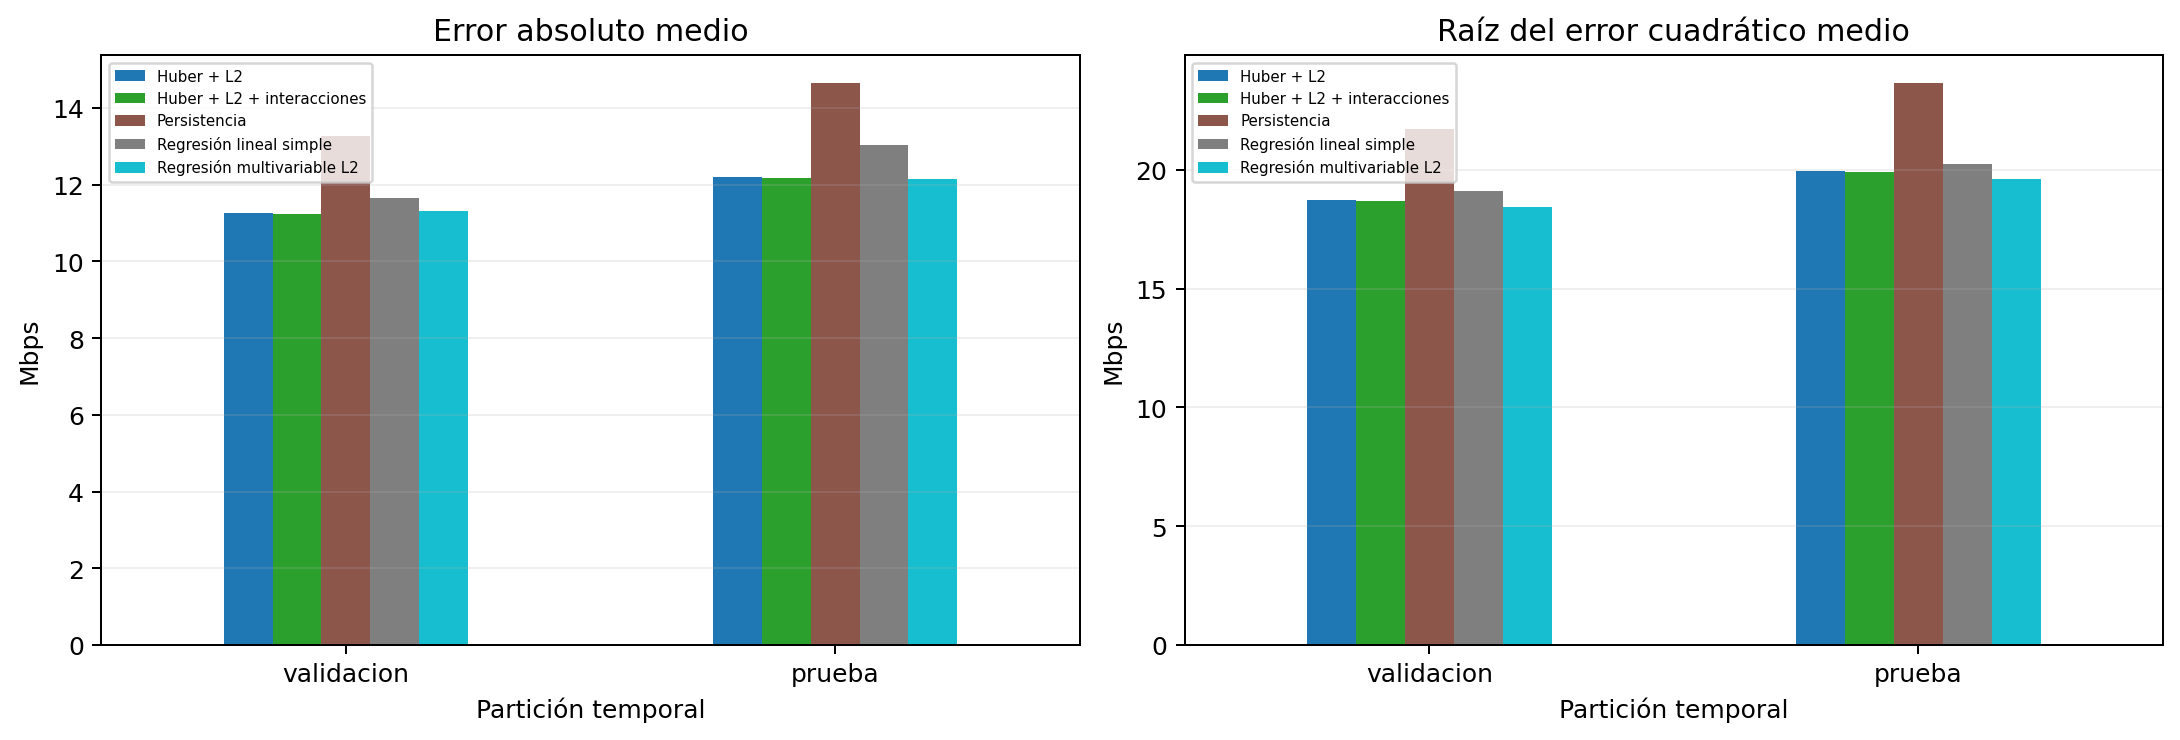

In [6]:
baseline = Pipeline(stages=[
    VectorAssembler(inputCols=["vel_t"], outputCol="base_features"),
    LinearRegression(featuresCol="base_features", labelCol="objetivo",
                     predictionCol="pred_lr_base", regParam=0.0, solver="normal"),
]).fit(train_df)
sufficiency_filter = (F.col("tests") >= MIN_TESTS) & (F.col("teselas_observadas") >= MIN_TILES)
comparison = []
test_scored = None
for partition, frame in [("validacion", val_df), ("prueba", test_df)]:
    scored = baseline.transform(frame)
    for stage in STAGES:
        stage_prediction = stage_models[stage["id"]].transform(frame).select(
            "ubigeo", "period_id", F.col("prediction").alias(f"pred_{stage['id']}")
        )
        scored = scored.join(stage_prediction, ["ubigeo", "period_id"], "inner")
    scored = cached(scored.withColumn("prediction", F.col(f"pred_{MODEL_NAME}")))
    if scored.count() != partition_sizes[partition]:
        raise ValueError("La comparación perdió o duplicó pares temporales.")
    model_columns = [("Persistencia", "vel_t"), ("Regresión lineal simple", "pred_lr_base")]
    model_columns += [(stage["name"], f"pred_{stage['id']}") for stage in STAGES]
    for segment, subset in [("Todos los pares", scored), ("Con suficiencia", scored.filter(sufficiency_filter))]:
        for name, column in model_columns:
            comparison.append({"particion": partition, "segmento": segment, "modelo": name,
                               **regression_metrics(subset, column)})
    if partition == "prueba":
        test_scored = scored
    else:
        scored.unpersist()
comparison_pdf = pd.DataFrame(comparison)
display(comparison_pdf.round(4))


def grouped_diagnostics(frame, groups):
    return frame.groupBy(*groups).agg(
        F.count("*").alias("pares"),
        F.avg(F.abs(F.col("vel_t") - F.col("objetivo"))).alias("mae_persistencia"),
        F.avg(F.abs(F.col("pred_lr_base") - F.col("objetivo"))).alias("mae_lineal"),
        F.avg(F.abs(F.col("prediction") - F.col("objetivo"))).alias("mae_huber"),
        F.sqrt(F.avg(F.pow(F.col("prediction") - F.col("objetivo"), 2))).alias("rmse_huber"),
        F.avg(F.col("prediction") - F.col("objetivo")).alias("sesgo_huber"),
        (1.0 - F.avg(F.pow(F.col("prediction") - F.col("objetivo"), 2))
         / F.when(F.var_pop("objetivo") > 0, F.var_pop("objetivo"))).alias("r2_huber"),
    ).orderBy(*groups).toPandas()


diagnostic_frame = test_scored.withColumn(
    "segmento", F.when(sufficiency_filter, "Con suficiencia").otherwise("Baja suficiencia"))
diagnostics_pdf = grouped_diagnostics(diagnostic_frame, ["departamento", "segmento"])
quarter_diagnostics_pdf = grouped_diagnostics(
    diagnostic_frame, ["year_objetivo", "quarter_objetivo", "segmento"])
display(diagnostics_pdf.round(3))
display(quarter_diagnostics_pdf.round(3))
clip_rows = []
for partition, frame in [("validacion", val_df), ("prueba", test_df)]:
    untrimmed = eval_model.transform(frame)
    clip_rows.append({"particion": partition, **untrimmed.agg(
        F.count("*").alias("pares"),
        F.avg((F.col("vel_t") + F.col("pred_delta_mbps") < 0).cast("double")).alias("fraccion_recortada_a_cero"),
    ).first().asDict()})
display(pd.DataFrame(clip_rows))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, metric, title in zip(axes, ["mae_mbps", "rmse_mbps"],
                             ["Error absoluto medio", "Raíz del error cuadrático medio"]):
    selected = comparison_pdf[comparison_pdf.segmento == "Todos los pares"].pivot(
        index="particion", columns="modelo", values=metric
    ).reindex(["validacion", "prueba"])
    selected.plot.bar(ax=ax, rot=0, colormap="tab10")
    ax.set(title=title, xlabel="Partición temporal", ylabel="Mbps")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=6)
chart_errors = persist_figure(fig, f"errores_{MODEL_NAME}.png")

**Coeficientes y reentrenamiento productivo**

El gráfico presenta el signo y la magnitud del coeficiente multiplicado por la
desviación de su característica en entrenamiento. Esta escala facilita comparar
características, pero no constituye importancia causal ni porcentaje de contribución.
La desviación se calcula sin ponderar para describir la distribución de predictores;
el ajuste mantiene los pesos de telemetría. Las variables constantes reciben magnitud cero.
Con interacciones, la asociación de una variable depende también de las variables
con las que se cruza; no corresponde interpretar aisladamente su coeficiente principal.

Los parámetros seleccionados quedan congelados. El modelo productivo vuelve a ajustar
su preprocesamiento y regresión con todos los pares observados. Se conservan ambos
PipelineModel en rutas distintas. La carga requiere las mismas características de entrada
y una versión compatible de Spark; esta libreta no despliega ni modifica SageMaker.

,variable,coeficiente,desviacion_entrenamiento,coeficiente_por_desviacion,magnitud
8,vel_ratio_depto_t_imputada,-4.0857,0.9135,-3.7321,3.7321
6,delta_vel_1t_imputada,-0.1124,14.0607,-1.5807,1.5807
7,vel_ratio_media_4t_imputada,-3.0413,0.4967,-1.5107,1.5107
21,inter_delta_historial,-0.0234,52.8506,-1.2347,1.2347
5,vel_std_4t_imputada,-0.1945,6.1600,-1.1982,1.1982
0,log_vel_t_imputada,-1.4061,0.7757,-1.0907,1.0907
12,historial_observado_4t_imputada,1.1665,0.7177,0.8372,0.8372
1,log_vel_lag1_imputada,-1.0118,0.7194,-0.7279,0.7279
20,inter_vel_pruebas,0.1131,5.4549,0.6170,0.6170
2,log_vel_lag2_imputada,0.7769,0.7176,0.5575,0.5575


,Indicador,Valor
0,Intercepto del cambio estimado (Mbps),8.806510
1,Escala residual Huber (Mbps),6.639229
2,Iteraciones de evaluación,35.000000


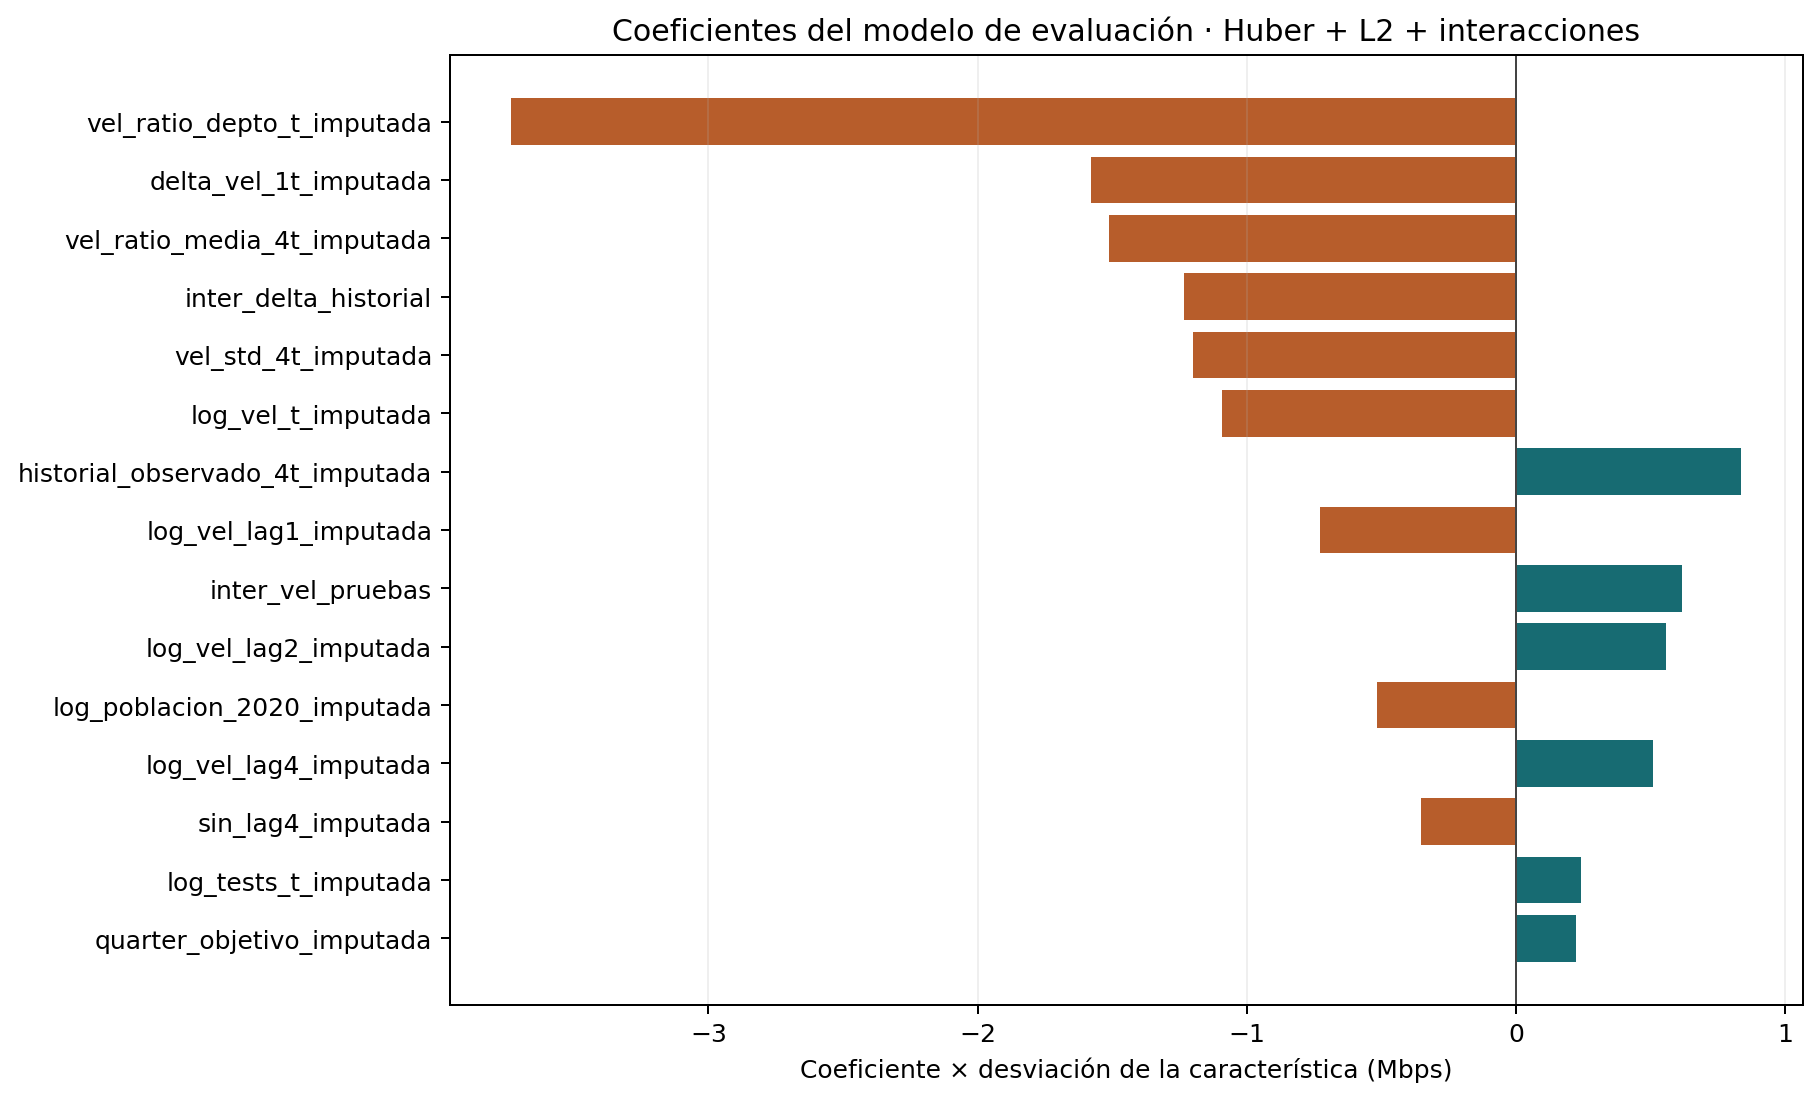

,Indicador,Valor
0,Pares productivos,35557
1,Tiempo productivo (s),23.0
2,Modelo de evaluación,s3://american-tower-dev-artifacts-74d328932631...
3,Modelo productivo,s3://american-tower-dev-artifacts-74d328932631...


In [7]:
from pyspark.ml.stat import Summarizer

evaluation_features = eval_preprocessor.transform(train_df)
vector_metadata = evaluation_features.schema["features"].metadata["ml_attr"]
attributes = [attribute for group in vector_metadata.get("attrs", {}).values() for attribute in group]
feature_names = {attribute["idx"]: attribute["name"] for attribute in attributes}
feature_count = int(vector_metadata["num_attrs"])
feature_std = evaluation_features.select(
    Summarizer.std(F.col("features")).alias("desviacion")
).first().desviacion
coefficients = eval_regression_model.coefficients
if len(coefficients) != feature_count or len(feature_std) != feature_count:
    raise ValueError("Los coeficientes no coinciden con el vector de características.")
coefficient_pdf = pd.DataFrame([
    {"variable": feature_names.get(index, f"f{index}"),
     "coeficiente": float(coefficients[index]), "desviacion_entrenamiento": float(feature_std[index]),
     "coeficiente_por_desviacion": float(coefficients[index] * feature_std[index])}
    for index in range(feature_count)
])
coefficient_pdf["magnitud"] = coefficient_pdf.coeficiente_por_desviacion.abs()
coefficient_pdf = coefficient_pdf.sort_values(["magnitud", "variable"], ascending=[False, True])
display(coefficient_pdf.head(20).round(4))
show_values({"Intercepto del cambio estimado (Mbps)": float(eval_regression_model.intercept),
             "Escala residual Huber (Mbps)": float(eval_regression_model.scale),
             "Iteraciones de evaluación": stage_diagnostics[MODEL_NAME]["iterations"]})
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
top_coefficients = coefficient_pdf.head(15).iloc[::-1]
ax.barh(top_coefficients.variable, top_coefficients.coeficiente_por_desviacion,
        color=["#176B72" if value >= 0 else "#B75D2B"
               for value in top_coefficients.coeficiente_por_desviacion])
ax.axvline(0, color="#444444", linewidth=0.8)
ax.set(title="Coeficientes del modelo de evaluación · Huber + L2 + interacciones",
       xlabel="Coeficiente × desviación de la característica (Mbps)")
ax.grid(axis="x", alpha=0.2)
chart_coefficients = persist_figure(fig, f"coeficientes_{MODEL_NAME}.png")

production_start = time.perf_counter()
assert_imputable(all_pairs, "reentrenamiento productivo")
prod_preprocessor = preprocessing_pipeline(True).fit(all_pairs)
production_features = cached(prod_preprocessor.transform(all_pairs))
production_count = production_features.count()
prod_regression_model = regression_estimator("huber", best_parameters).fit(production_features)
production_diagnostics = fit_diagnostics(prod_regression_model)
if production_diagnostics["iteration_limit_reached"]:
    print("Advertencia: el ajuste productivo alcanzó el límite de iteraciones.")
prod_model = PipelineModel(stages=prod_preprocessor.stages + [prod_regression_model, postprocessor])
prod_model.write().save(PROD_MODEL_URI)
production_seconds = time.perf_counter() - production_start
production_features.unpersist()
show_values({"Pares productivos": production_count, "Tiempo productivo (s)": round(production_seconds, 2),
             "Modelo de evaluación": EVAL_MODEL_URI, "Modelo productivo": PROD_MODEL_URI})

**Pronóstico y preselección territorial**

El índice conserva los pesos del notebook 06: 40 % velocidad proyectada, 35 % población
y 25 % brecha de cobertura declarada. Es una herramienta de preselección para estudios
posteriores. La suficiencia requiere diez pruebas, dos teselas y una predicción válida.
Los distritos sin medición o con bajo soporte conservan un índice nulo y aparecen en gris.
La falta de reporte OSIPTEL se identifica por separado y no se interpreta como ausencia
de infraestructura. La población se ordena sobre el universo completo; la velocidad,
sobre los distritos aptos. Los empates se resuelven por UBIGEO para destacar hasta 50 distritos.

In [8]:
def period_label(period_id):
    return f"{period_id // 4}-T{period_id % 4 + 1}"


def score_quarter(period_id):
    quarter = features_full.filter(F.col("period_id") == period_id)
    observed = quarter.filter(F.col("vel_t").isNotNull())
    unobserved = quarter.filter(F.col("vel_t").isNull()).withColumn("prediction", F.lit(None).cast("double"))
    cols = ["ubigeo", "departamento", "provincia", "distrito", "year", "quarter", "period_id",
            "year_objetivo", "quarter_objetivo", "observado", "vel_t", "tests", "teselas_observadas",
            "poblacion_2020", F.col("prediction").alias("pred_descarga_mbps")]
    scored = prod_model.transform(observed).select(*cols).unionByName(unobserved.select(*cols))
    context_cols = ["ubigeo", "pct_cobertura_4g_raw", "pct_cobertura_4g_imputada", "cobertura_imputada",
                    "en_punto_ciego_osiptel", "periodo_referencia", "fecha_corte_fuente"]
    result = (scored.join(priority_context.select(*context_cols), "ubigeo", "left")
              .orderBy("ubigeo").limit(EXPECTED_DISTRICTS + 1).toPandas())
    if len(result) != EXPECTED_DISTRICTS or result.ubigeo.nunique() != EXPECTED_DISTRICTS:
        raise ValueError("El pronóstico no conserva el universo distrital.")
    measured = result.vel_t.notna()
    if not np.isfinite(result.loc[measured, "pred_descarga_mbps"]).all():
        raise ValueError("Existen predicciones no finitas en distritos observados.")
    return result


def compute_priority_index(scored_pdf, weights=PRIORITY_WEIGHTS):
    if len(weights) != 3 or any(w < 0 for w in weights) or not math.isclose(sum(weights), 1.0):
        raise ValueError("Los tres pesos deben ser no negativos y sumar uno.")
    result = scored_pdf.copy().sort_values("ubigeo").reset_index(drop=True)
    observed = result.vel_t.notna() & result.pred_descarga_mbps.notna()
    sufficient = observed & (result.tests.fillna(0) >= MIN_TESTS) & (result.teselas_observadas.fillna(0) >= MIN_TILES)
    result["suficiencia"] = np.where(~observed, "Punto ciego sin telemetría",
                                      np.where(sufficient, "Apto con suficiencia", "Baja suficiencia"))
    result["score_vel"] = np.nan
    result.loc[sufficient, "score_vel"] = 1.0 - result.loc[sufficient, "pred_descarga_mbps"].rank(pct=True)
    result["score_pop"] = np.log1p(result.poblacion_2020).rank(pct=True)
    result["score_cov"] = 1.0 - result.pct_cobertura_4g_imputada.clip(0, 100) / 100.0
    result["indice_prioridad"] = np.nan
    result.loc[sufficient, "indice_prioridad"] = 100.0 * (
        weights[0] * result.loc[sufficient, "score_vel"]
        + weights[1] * result.loc[sufficient, "score_pop"]
        + weights[2] * result.loc[sufficient, "score_cov"]
    )
    if result.loc[sufficient, "indice_prioridad"].isna().any():
        raise ValueError("Un distrito apto carece de contexto suficiente para calcular su índice.")
    result["ranking_prioridad"] = pd.Series(pd.NA, index=result.index, dtype="Int64")
    eligible = result.loc[sufficient].sort_values(["indice_prioridad", "ubigeo"], ascending=[False, True])
    result.loc[eligible.index, "ranking_prioridad"] = np.arange(1, len(eligible) + 1)
    return result


previous_period, current_period = periods[-2:]
if current_period != previous_period + 1:
    raise ValueError("La estabilidad temporal requiere dos trimestres consecutivos.")
lbl_prev, lbl_curr, lbl_target = map(period_label, [previous_period, current_period, current_period + 1])
pdf_prev = compute_priority_index(score_quarter(previous_period))
pdf_curr = compute_priority_index(score_quarter(current_period))
top_districts = pdf_curr.dropna(subset=["indice_prioridad"]).sort_values("ranking_prioridad").head(TOP_K)
display(pdf_curr.suficiencia.value_counts().rename_axis("suficiencia").reset_index(name="distritos"))
display(top_districts[["ranking_prioridad", "ubigeo", "departamento", "distrito", "vel_t",
                       "pred_descarga_mbps", "tests", "poblacion_2020", "pct_cobertura_4g_raw",
                       "cobertura_imputada", "indice_prioridad"]].head(20))
show_values({"Trimestre de origen": lbl_curr, "Trimestre pronosticado": lbl_target,
             "Distritos con predicción": int(pdf_curr.pred_descarga_mbps.notna().sum()),
             "Distritos aptos": len(pdf_curr.dropna(subset=["indice_prioridad"])),
             "Distritos con cobertura imputada": int(pdf_curr.cobertura_imputada.sum())})

,suficiencia,distritos
0,Apto con suficiencia,1019
1,Baja suficiencia,545
2,Punto ciego sin telemetría,326


,ranking_prioridad,ubigeo,departamento,distrito,vel_t,pred_descarga_mbps,tests,poblacion_2020,pct_cobertura_4g_raw,cobertura_imputada,indice_prioridad
1798,1,220708,SAN MARTIN,SHAMBOYACU,4.803182,17.791541,11.0,19030.413302,0.000000,False,93.803729
1488,2,160404,LORETO,SAN PABLO,14.965923,18.233576,26.0,16897.557396,NaN,True,93.262258
1487,3,160403,LORETO,YAVARI,30.834896,24.125732,77.0,20381.486882,0.000000,False,93.017210
1484,4,160305,LORETO,URARINAS,25.208933,22.297685,15.0,16489.540749,0.000000,False,92.529731
1500,5,160601,LORETO,CONTAMANA,16.356784,24.068533,125.0,30682.407224,11.111111,False,92.151274
1092,6,120303,JUNIN,PICHANAQUI,23.422833,30.689931,288.0,93373.957888,9.523810,False,91.947020
1486,7,160402,LORETO,PEBAS,31.127129,27.049220,31.0,19632.801376,0.000000,False,91.904009
1506,8,160701,LORETO,BARRANCA,32.613792,28.002821,24.0,19416.728133,NaN,True,91.455912
1485,9,160401,LORETO,RAMON CASTILLA,18.484815,23.447190,216.0,30843.334313,16.666667,False,90.898666
484,10,050502,AYACUCHO,ANCO,11.688700,23.229612,10.0,14964.423591,3.846154,False,90.760811


,Indicador,Valor
0,Trimestre de origen,2026-T1
1,Trimestre pronosticado,2026-T2
2,Distritos con predicción,1564
3,Distritos aptos,1019
4,Distritos con cobertura imputada,227


**Estabilidad temporal y sensibilidad del índice**

Se compara la coincidencia entre los primeros distritos de los dos trimestres más
recientes y se modifica la ponderación del índice. Ambos trimestres se puntúan con
el mismo modelo productivo; esta comparación describe estabilidad retrospectiva del
ranking, no una nueva prueba predictiva fuera de muestra.

In [9]:
def stability_metrics(first, second, k):
    first = first.dropna(subset=["indice_prioridad"])
    second = second.dropna(subset=["indice_prioridad"])
    top_first = set(first.sort_values("ranking_prioridad").head(k).ubigeo)
    top_second = set(second.sort_values("ranking_prioridad").head(k).ubigeo)
    common = first[["ubigeo", "indice_prioridad"]].merge(
        second[["ubigeo", "indice_prioridad"]], on="ubigeo", suffixes=("_a", "_b")
    )
    overlap = len(top_first & top_second)
    union = len(top_first | top_second)
    denominator = min(len(top_first), len(top_second))
    spearman = (common.indice_prioridad_a.rank().corr(common.indice_prioridad_b.rank())
                if len(common) > 1 else None)
    return {"top_k_solicitado": k, "top_a": len(top_first), "top_b": len(top_second),
            "coincidencias": overlap, "overlap_pct": 100.0 * overlap / denominator if denominator else None,
            "jaccard": overlap / union if union else None, "spearman": spearman,
            "distritos_comunes": len(common)}


stability_rows = [{"prueba": f"Temporal {lbl_prev} vs {lbl_curr}",
                   **stability_metrics(pdf_prev, pdf_curr, TOP_K)}]
for label, weights in [
    ("Mayor peso velocidad 50/30/20", (0.50, 0.30, 0.20)),
    ("Mayor peso población 30/45/25", (0.30, 0.45, 0.25)),
    ("Mayor peso cobertura 30/30/40", (0.30, 0.30, 0.40)),
]:
    alternative = compute_priority_index(pdf_curr, weights)
    stability_rows.append({"prueba": label, **stability_metrics(pdf_curr, alternative, TOP_K)})
display(pd.DataFrame(stability_rows).round(4))

,prueba,top_k_solicitado,top_a,top_b,coincidencias,overlap_pct,jaccard,spearman,distritos_comunes
0,Temporal 2025-T4 vs 2026-T1,50,50,50,35,70.0,0.5385,0.7966,866
1,Mayor peso velocidad 50/30/20,50,50,50,44,88.0,0.7857,0.9840,1019
2,Mayor peso población 30/45/25,50,50,50,45,90.0,0.8182,0.9663,1019
3,Mayor peso cobertura 30/30/40,50,50,50,41,82.0,0.6949,0.9433,1019


**Publicación y evidencias**

Las predicciones respetan el esquema de la tabla Glue `predicciones_modelos`. El índice
permanece nulo cuando no existe suficiencia; no se publica como cero. Las salidas de los
otros integrantes permanecen intactas. Se conserva una copia de todos los distritos en
Operations, incluida la clasificación de suficiencia. El manifiesto final se completa
después de generar el mapa.

In [10]:
prediction_schema = pa.schema([
    ("inference_id", pa.string()), ("inference_timestamp", pa.timestamp("us")),
    ("modelo", pa.string()), ("autor", pa.string()), ("ubigeo", pa.string()),
    ("year_objetivo", pa.int32()), ("quarter_objetivo", pa.int32()),
    ("vel_origen_mbps", pa.float64()), ("pred_descarga_mbps", pa.float64()),
    ("indice_prioridad", pa.float64()),
])
export = pdf_curr[pdf_curr.pred_descarga_mbps.notna()].copy()
prediction_pdf = pd.DataFrame({
    "inference_id": RUN_ID, "inference_timestamp": datetime.now(timezone.utc).replace(tzinfo=None),
    "modelo": MODEL_NAME, "autor": MODEL_AUTHOR, "ubigeo": export.ubigeo.astype(str).str.zfill(6),
    "year_objetivo": export.year_objetivo.astype("int32"),
    "quarter_objetivo": export.quarter_objetivo.astype("int32"),
    "vel_origen_mbps": export.vel_t.astype("float64"),
    "pred_descarga_mbps": export.pred_descarga_mbps.astype("float64"),
    "indice_prioridad": export.indice_prioridad.astype("float64"),
})
local_prediction = LOCAL_OUTPUT_DIR / f"modelo_{MODEL_NAME}.parquet"
pq.write_table(pa.Table.from_pandas(prediction_pdf, schema=prediction_schema, preserve_index=False),
               local_prediction, compression="snappy")
published_gold_uri = None
if PUBLISH_PREDICTIONS_TO_GOLD:
    s3.upload_file(str(local_prediction), GOLD_BUCKET, PREDICTIONS_GOLD_KEY)
    published_gold_uri = f"s3://{GOLD_BUCKET}/{PREDICTIONS_GOLD_KEY}"

territorial_path = LOCAL_OUTPUT_DIR / "priorizacion_todos_los_distritos.parquet"
pq.write_table(pa.Table.from_pandas(pdf_curr, preserve_index=False), territorial_path, compression="snappy")
territorial_bucket, territorial_key = s3_path(f"{OUT_OPS_ROOT}/{territorial_path.name}")
s3.upload_file(str(territorial_path), territorial_bucket, territorial_key)
report = {
    "run_id": RUN_ID, "modelo": MODEL_NAME, "autor": MODEL_AUTHOR,
    "gold_manifest_uri": GOLD_RUN_URI, "bronze_manifest_uri": gold_manifest["bronze_manifest_uri"],
    "application_id": spark.sparkContext.applicationId, "spark_version": spark.version,
    "spark_event_log_uri": events_uri, "dependencies": dependency_versions,
    "spark_environment": spark_environment,
    "label": "objetivo_delta_mbps", "features": FEATURE_NUMERIC_COLS + ["departamento_ohe"],
    "interactions": [{"name": name, "left": left, "right": right} for name, left, right in INTERACTIONS],
    "loss": "huber", "elastic_net_param": 0.0, "weight": "log1p(tests_t)",
    "standardization": True, "max_iter": MAX_ITER, "tol": TOLERANCE,
    "evaluation_origin_min_year": 2020, "partitions": partition_rows,
    "worldpop_reference_year": 2020, "osiptel_predictor": False,
    "osiptel_priority_snapshot": coverage_snapshot,
    "parameter_search": tuning_rows, "best_parameters": best_parameters,
    "stage_parameters": stage_parameters, "stage_fit_diagnostics": stage_diagnostics,
    "production_fit_diagnostics": production_diagnostics,
    "test_by_quarter": quarter_diagnostics_pdf.to_dict("records"), "clipping": clip_rows,
    "comparison": comparison, "test_by_department": diagnostics_pdf.to_dict("records"),
    "eval_model_uri": EVAL_MODEL_URI, "production_model_uri": PROD_MODEL_URI,
    "production_pairs": production_count, "production_seconds": production_seconds,
    "prediction_period": lbl_target, "predictions_gold_uri": published_gold_uri,
    "districts_with_prediction": len(export), "districts_in_panel": len(pdf_curr),
    "sufficiency": pdf_curr.suficiencia.value_counts().to_dict(),
    "priority_weights": dict(zip(["velocidad", "poblacion", "cobertura"], PRIORITY_WEIGHTS)),
    "minimum_tests": MIN_TESTS, "minimum_tiles": MIN_TILES,
    "stability": stability_rows, "evaluation_coefficients": coefficient_pdf.to_dict("records"),
    "evaluation_intercept": float(eval_regression_model.intercept),
    "territorial_output": f"s3://{territorial_bucket}/{territorial_key}",
    "charts": {"errores": chart_errors, "coeficientes": chart_coefficients},
}
show_values({"Predicciones Gold": published_gold_uri or "Publicación desactivada",
             "Modelo productivo": PROD_MODEL_URI,
             "Directorio local": str(LOCAL_OUTPUT_DIR),
             "Distritos con predicción": len(export)})

,Indicador,Valor
0,Predicciones Gold,s3://american-tower-dev-gold-00f4f2b4cf37bac32...
1,Modelo productivo,s3://american-tower-dev-artifacts-74d328932631...
2,Directorio local,/mnt/american-tower-cache/huber_l2_interaccion...
3,Distritos con predicción,1564


**Mapa final de preselección territorial**

La cartografía procede del mismo `Distrito.rar` del manifiesto Bronze y se verifica
con SHA-256 antes de extraer el GeoPackage. El mapa mantiene el universo completo,
utiliza una escala fija de 0 a 100 y destaca hasta 50 distritos mediante bordes y puntos
azules. Los diez primeros se etiquetan con su posición y nombre. Los distritos sin índice
se muestran en gris. El PNG se guarda localmente y en Operations; la imagen constituye
la última salida visible de la libreta. La distribución territorial dependerá de las
predicciones de Huber + L2 + interacciones y no reproducirá necesariamente el ranking del GBT.

,Indicador,Valor
0,Reporte,s3://american-tower-dev-operations-1dd72256126...
1,Mapa local,/mnt/american-tower-cache/huber_l2_interaccion...
2,Mapa S3,s3://american-tower-dev-operations-1dd72256126...


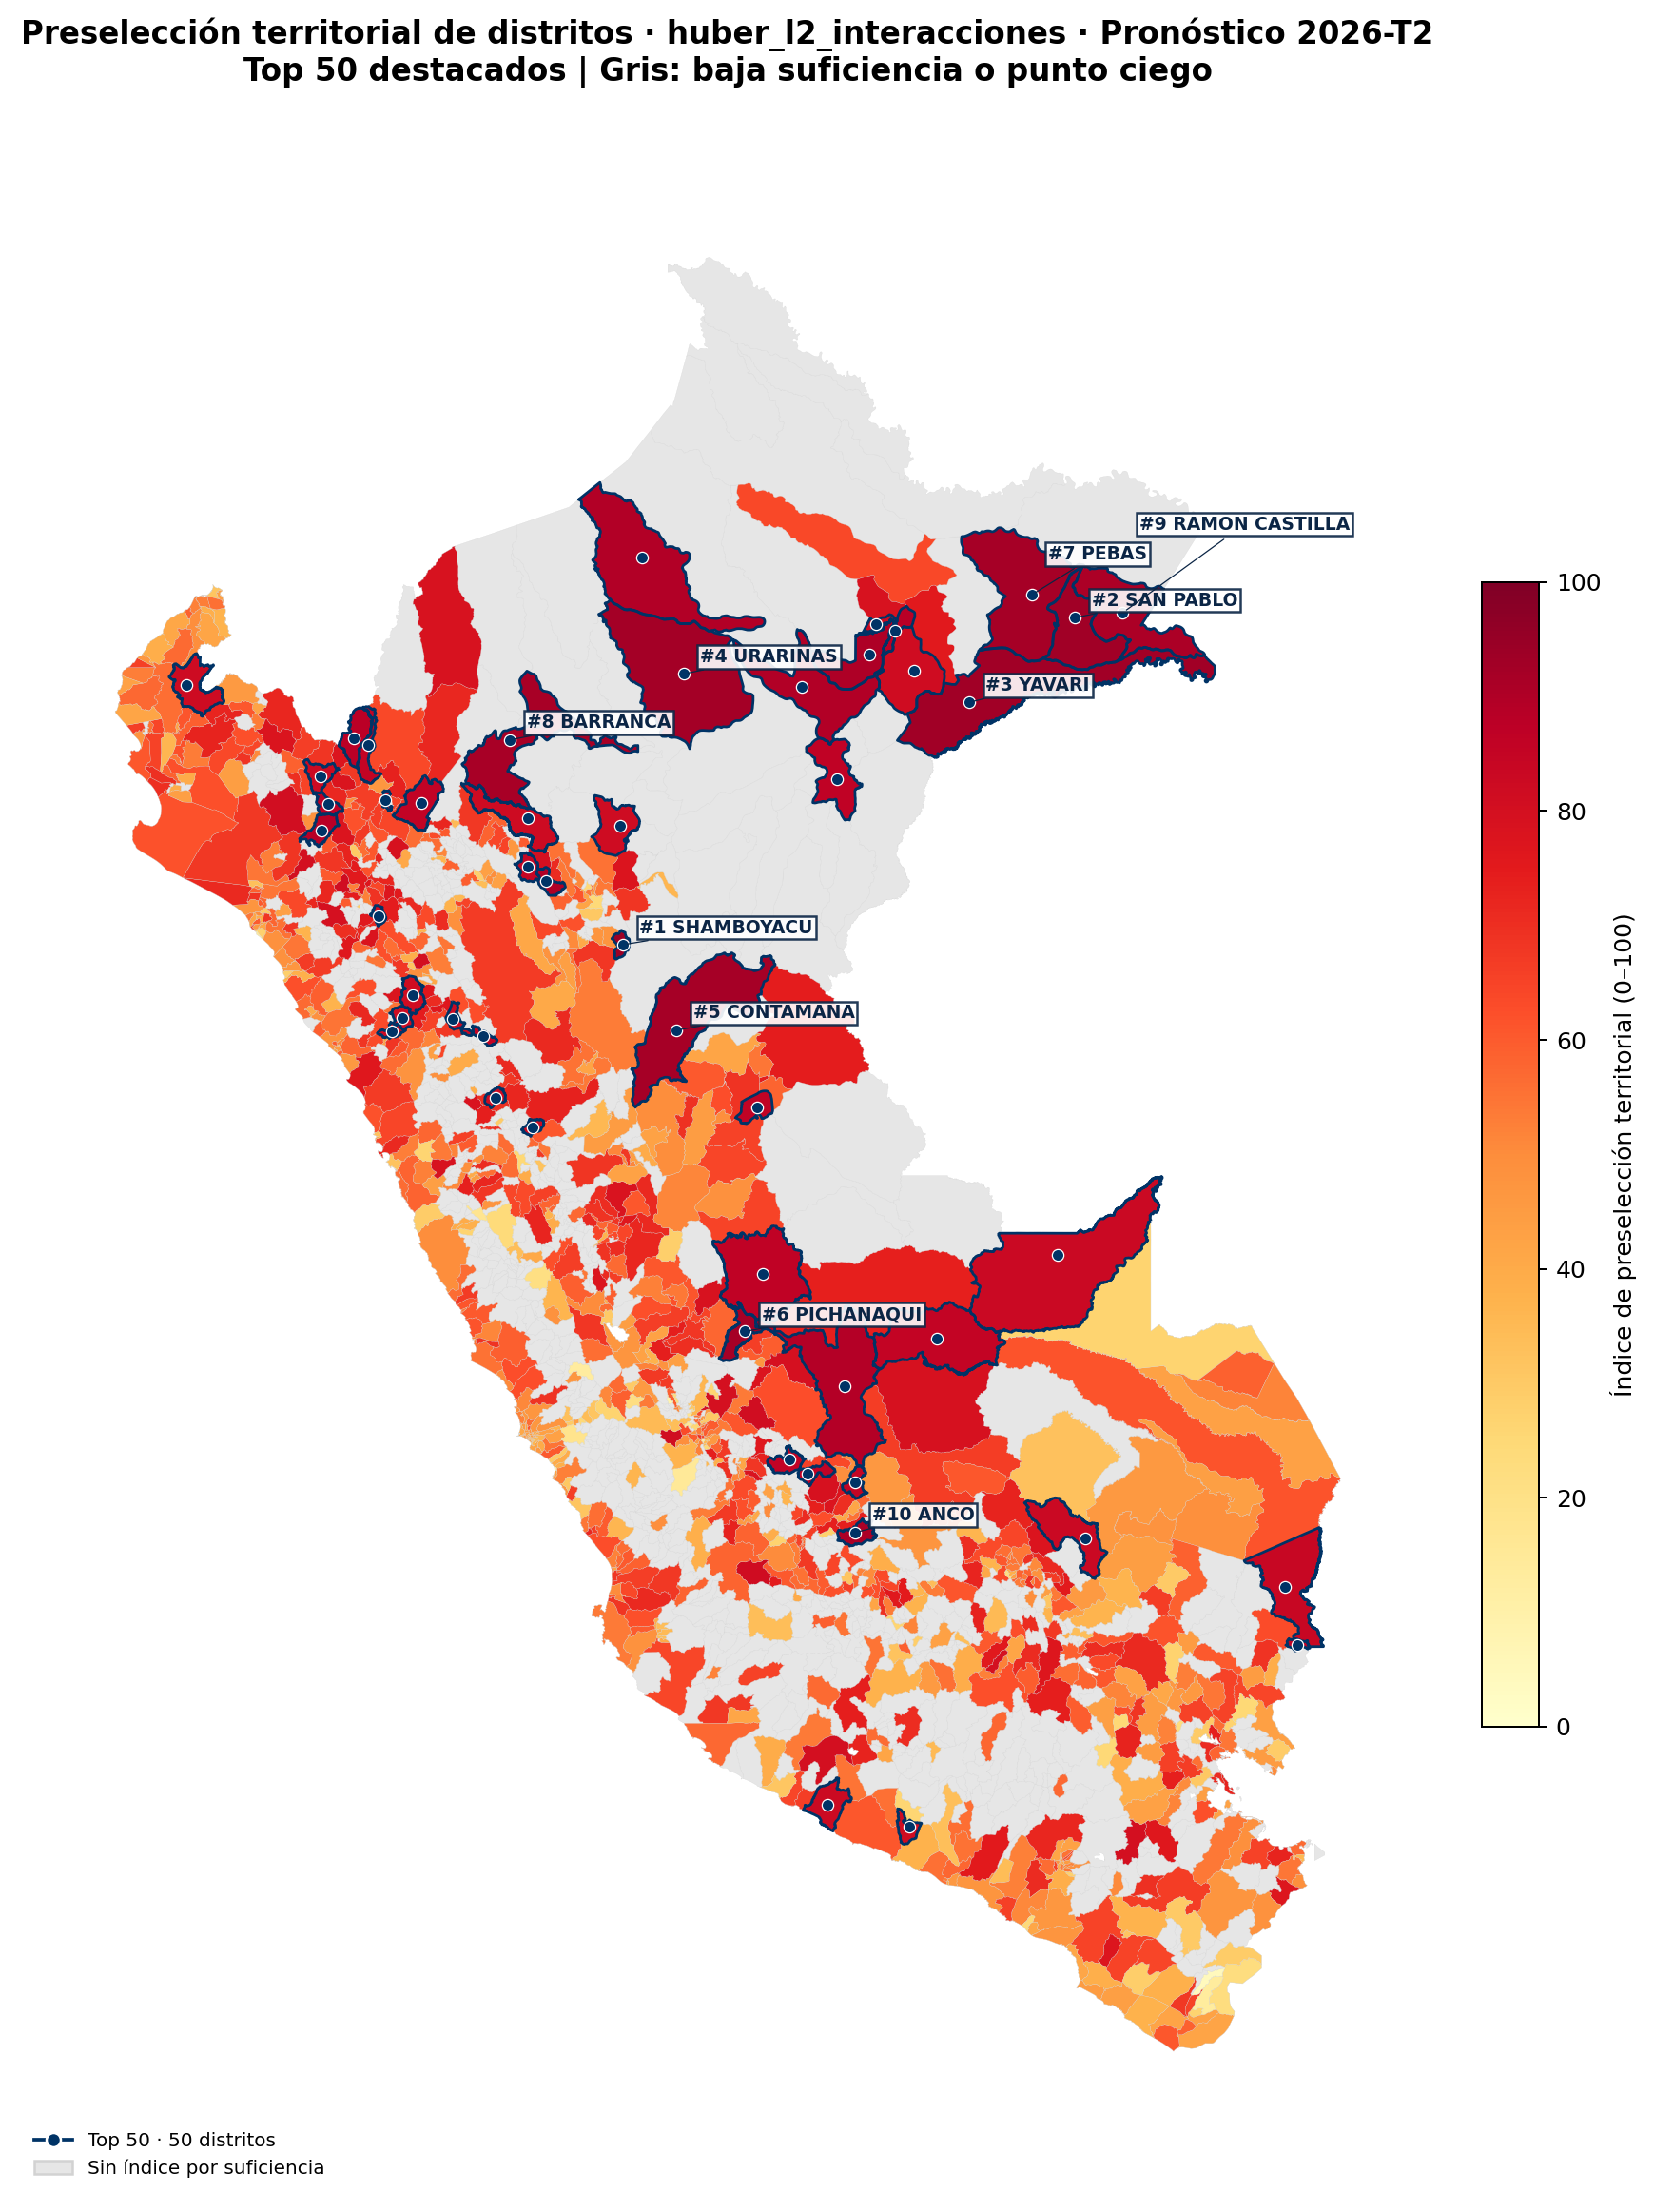

In [11]:
import geopandas as gpd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import Normalize

archive_items = [item for item in bronze_manifest["objects"]
                 if item["source"] == "inei" and PurePosixPath(item["key"]).name.lower() == "distrito.rar"]
if len(archive_items) != 1:
    raise ValueError("El manifiesto Bronze no identifica un único Distrito.rar.")
if shutil.which("bsdtar") is None:
    raise RuntimeError("Se requiere bsdtar, incluido en el bootstrap de EMR.")
archive_item = archive_items[0]
archive_path = CACHE_DIR / "Distrito.rar"
download_arguments = {"VersionId": archive_item["version_id"]} if archive_item.get("version_id") else {}
s3.download_file(archive_item["bucket"], archive_item["key"], str(archive_path), ExtraArgs=download_arguments)
digest = hashlib.sha256()
with archive_path.open("rb") as stream:
    for chunk in iter(lambda: stream.read(8 * 1024**2), b""):
        digest.update(chunk)
if digest.hexdigest() != archive_item["sha256"]:
    raise ValueError("La cartografía descargada difiere de la huella SHA-256 de Bronze.")
members = subprocess.check_output(["bsdtar", "-tf", str(archive_path)], text=True).splitlines()
gpkg_members = [name for name in members if name.lower().endswith(".gpkg")]
if len(gpkg_members) != 1:
    raise ValueError("Distrito.rar debe contener un único GeoPackage.")
gpkg_path = CACHE_DIR / "DISTRITO.gpkg"
with gpkg_path.open("wb") as target:
    subprocess.run(["bsdtar", "-xOf", str(archive_path), gpkg_members[0]], stdout=target, check=True)

districts_geo = gpd.read_file(gpkg_path)
districts_geo.columns = districts_geo.columns.str.strip().str.lower()
if "ubigeo" not in districts_geo or districts_geo.crs is None:
    raise ValueError("La cartografía requiere UBIGEO y un CRS declarado.")
districts_geo = districts_geo[["ubigeo", "geometry"]].copy().to_crs(4326)
districts_geo["ubigeo"] = districts_geo.ubigeo.astype("string").str.strip().str.zfill(6)
districts_geo["geometry"] = districts_geo.geometry.make_valid()
districts_geo = districts_geo.explode(index_parts=False).reset_index(drop=True)
districts_geo = districts_geo[districts_geo.geom_type.isin(["Polygon", "MultiPolygon"])]
districts_geo = districts_geo.dissolve(by="ubigeo", as_index=False)
if len(districts_geo) != EXPECTED_DISTRICTS or districts_geo.geometry.is_empty.any():
    raise ValueError("La cartografía reparada no conserva los 1,890 distritos.")
if set(districts_geo.ubigeo) != set(pdf_curr.ubigeo):
    raise ValueError("La cartografía y la priorización contienen universos distritales diferentes.")
mapa = districts_geo.merge(
    pdf_curr[["ubigeo", "distrito", "suficiencia", "indice_prioridad", "ranking_prioridad"]],
    on="ubigeo", how="left", validate="one_to_one",
)
selected_codes = set(top_districts.ubigeo)
highlighted = mapa[mapa.ubigeo.isin(selected_codes)].copy()
top10 = highlighted.sort_values("ranking_prioridad").head(10).copy()
# Los puntos representativos permanecen dentro del distrito, incluso en polígonos irregulares.
highlight_points = highlighted.to_crs(6933).geometry.representative_point().to_crs(4326)
label_points = top10.to_crs(6933).geometry.representative_point().to_crs(4326)

fig, ax = plt.subplots(figsize=(11, 13))
mapa.plot(ax=ax, color="#e6e6e6", linewidth=0.10, edgecolor="#d2d2d2")
with_index = mapa[mapa.indice_prioridad.notna()]
if not with_index.empty:
    with_index.plot(ax=ax, column="indice_prioridad", cmap="YlOrRd", vmin=0, vmax=100,
                    linewidth=0.10, edgecolor="#d8d8d8", legend=False)
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, 100), cmap="YlOrRd"),
                       ax=ax, shrink=0.55, fraction=0.04, pad=0.025)
colorbar.set_label("Índice de preselección territorial (0–100)")
if not highlighted.empty:
    highlighted.boundary.plot(ax=ax, color="#003366", linewidth=1.1, zorder=3)
    ax.scatter(highlight_points.x, highlight_points.y, s=24, color="#003366",
               edgecolor="white", linewidth=0.5, zorder=4)

# Las posiciones iniciales se distribuyen en pantalla y se separan cuando las etiquetas se solapan.
annotations = []
for (_, row), point in zip(top10.iterrows(), label_points):
    annotation = ax.annotate(
        f"#{int(row.ranking_prioridad)} {row.distrito}", xy=(point.x, point.y),
        xytext=(7, 5), textcoords="offset points", fontsize=7.5, fontweight="bold",
        color="#0b2545", bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="#0b2545", alpha=0.90),
        arrowprops=dict(arrowstyle="-", color="#0b2545", linewidth=0.5), zorder=5,
    )
    annotations.append(annotation)
ax.set_title(
    f"Preselección territorial de distritos · {MODEL_NAME} · Pronóstico {lbl_target}\n"
    f"Top {TOP_K} destacados | Gris: baja suficiencia o punto ciego",
    fontsize=13, fontweight="bold", pad=14,
)
ax.set_axis_off()
ax.margins(0.08)
ax.legend(handles=[
    Line2D([0], [0], marker="o", color="#003366", markeredgecolor="white", markersize=6,
           label=f"Top {TOP_K} · {len(highlighted)} distritos"),
    Patch(facecolor="#e6e6e6", edgecolor="#d2d2d2", label="Sin índice por suficiencia"),
], loc="lower left", frameon=False, fontsize=8)
fig.tight_layout()
for _ in range(30):
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    moved = False
    for index, annotation in enumerate(annotations):
        bounds = annotation.get_bbox_patch().get_window_extent(renderer).expanded(1.03, 1.12)
        if any(bounds.overlaps(previous.get_bbox_patch().get_window_extent(renderer))
               for previous in annotations[:index]):
            x_offset, y_offset = annotation.get_position()
            annotation.set_position((x_offset, y_offset + 10))
            moved = True
    if not moved:
        break

chart_map = persist_figure(fig, f"mapa_priorizacion_{MODEL_NAME}.png", show=False)
report["charts"]["mapa_peru"] = chart_map
report_uri = save_json_s3(f"{OUT_OPS_ROOT}/metricas_modelo.json", report)
save_json_s3(f"{OUT_OPS_ROOT}/_SUCCESS.json", {
    "run_id": RUN_ID, "modelo": MODEL_NAME, "gold_manifest_uri": GOLD_RUN_URI,
    "report_uri": report_uri, "model_uri": PROD_MODEL_URI,
    "predictions_gold_uri": published_gold_uri, "map_uri": chart_map["s3"],
})
show_values({"Reporte": report_uri, "Mapa local": chart_map["local"], "Mapa S3": chart_map["s3"]})
resources.close()
display(Image(filename=chart_map["local"]))

**Publicación y verificación final en Gold para Athena y QuickSight**

La celda sigue el mecanismo del notebook 06: las predicciones se publican como
Parquet en `predicciones_modelos/` del bucket Gold. El dataset de inferencias del
proyecto está configurado para consultar esa tabla mediante Athena en DIRECT_QUERY.
No se consulta ni modifica la API de QuickSight y no se requieren permisos nuevos
para describir su dataset o iniciar ingestas.

Cuando el archivo local generado por la celda de publicación continúa disponible,
se valida y se vuelve a subir al mismo objeto del modelo, respetando el indicador
`PUBLISH_PREDICTIONS_TO_GOLD`. Si el kernel se reinició y ese archivo no está
identificado en memoria, se descarga y verifica la publicación ya existente en S3.
La celda no vuelve a entrenar ni genera nuevas predicciones o fechas de inferencia.
Los índices ausentes se conservan nulos.

La comprobación acredita el contenido publicado en S3; no certifica los filtros ni
la configuración desplegada de Athena o QuickSight. Después de la publicación,
corresponde volver a abrir el análisis asociado a «Inferencias de Modelos» y revisar
el filtro `modelo = huber_l2_interacciones`, la autora y el periodo objetivo.


In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory

import boto3
import pyarrow.parquet as pq


def publicar_y_verificar_predicciones_gold(local_path=None, publicar=True):
    model_name = "huber_l2_interacciones"
    author = "Alba Malca"
    region = os.environ.get("AWS_REGION", "us-east-1")
    gold_bucket = os.environ.get("AT_GOLD_BUCKET", "american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee")
    gold_key = f"predicciones_modelos/modelo_{model_name}.parquet"
    gold_uri = f"s3://{gold_bucket}/{gold_key}"
    storage = boto3.client("s3", region_name=region)
    required = {"inference_id", "inference_timestamp", "modelo", "autor", "ubigeo",
                "year_objetivo", "quarter_objetivo", "vel_origen_mbps",
                "pred_descarga_mbps", "indice_prioridad"}

    with TemporaryDirectory(prefix="at-publicacion-gold-") as temp_dir:
        from_local = local_path is not None and publicar
        if from_local:
            prediction_path = Path(local_path)
            if not prediction_path.is_file():
                raise FileNotFoundError(f"El archivo local identificado no existe: {prediction_path}")
        else:
            prediction_path = Path(temp_dir) / "predicciones.parquet"
            storage.download_file(gold_bucket, gold_key, str(prediction_path))
        with pq.ParquetFile(prediction_path) as parquet:
            missing = required - set(parquet.schema_arrow.names)
            if missing:
                raise ValueError(f"Faltan columnas del contrato de predicciones: {sorted(missing)}")
            row_count = parquet.metadata.num_rows
            if not 0 < row_count <= 1890:
                raise ValueError(f"Cantidad inesperada de predicciones: {row_count}")
            published = parquet.read(columns=["modelo", "autor", "ubigeo", "year_objetivo",
                                               "quarter_objetivo", "indice_prioridad"])
        if set(published.column("modelo").to_pylist()) != {model_name}:
            raise ValueError("El archivo no contiene exclusivamente el modelo esperado.")
        if set(published.column("autor").to_pylist()) != {author}:
            raise ValueError("El archivo no identifica a Alba Malca como autora.")
        district_codes = published.column("ubigeo").to_pylist()
        if len(set(district_codes)) != row_count or any(
                not isinstance(code, str) or len(code) != 6 or not code.isdigit() for code in district_codes):
            raise ValueError("Las predicciones requieren un UBIGEO único de seis dígitos por distrito.")
        periods = set(zip(published.column("year_objetivo").to_pylist(),
                          published.column("quarter_objetivo").to_pylist()))
        if len(periods) != 1 or any(year is None or quarter not in (1, 2, 3, 4) for year, quarter in periods):
            raise ValueError("La publicación requiere un único periodo objetivo válido.")
        year, quarter = next(iter(periods))
        if from_local:
            storage.upload_file(str(prediction_path), gold_bucket, gold_key)
            operation = "Archivo local validado y publicado en Gold"
        else:
            operation = "Publicación existente en Gold descargada y verificada"

    print(operation)
    print(f"Predicciones: {gold_uri}")
    print(f"Modelo: {model_name} | Autora: {author} | Filas: {row_count} | Periodo: {year}-T{quarter}")
    print(f"Predicciones con índice nulo por suficiencia: {published.column('indice_prioridad').null_count}")
    print("Se conserva el contrato de publicación del notebook 06 y no se realizan llamadas a QuickSight.")
    print("Corresponde volver a abrir el análisis o dashboard asociado a Inferencias de Modelos.")
    print(f"Corresponde revisar los filtros modelo = {model_name}, autor = {author} y periodo = {year}-T{quarter}.")
    print("La presencia del archivo en Gold no verifica los filtros ni la consulta desplegada en QuickSight.")
    return {"predictions_gold_uri": gold_uri, "rows": row_count, "publication_action": operation}


resultado_publicacion_gold = publicar_y_verificar_predicciones_gold(
    local_path=globals().get("local_prediction"),
    publicar=globals().get("PUBLISH_PREDICTIONS_TO_GOLD", True),
)


Publicación existente en Gold descargada y verificada
Predicciones: s3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/predicciones_modelos/modelo_huber_l2_interacciones.parquet
Modelo: huber_l2_interacciones | Autora: Alba Malca | Filas: 1564 | Periodo: 2026-T2
Predicciones con índice nulo por suficiencia: 545
Se conserva el contrato de publicación del notebook 06 y no se realizan llamadas a QuickSight.
Corresponde volver a abrir el análisis o dashboard asociado a Inferencias de Modelos.
Corresponde revisar los filtros modelo = huber_l2_interacciones, autor = Alba Malca y periodo = 2026-T2.
La presencia del archivo en Gold no verifica los filtros ni la consulta desplegada en QuickSight.


/opt/american-tower/venv/lib64/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
